# Tecnológico de Monterrey
## Proyecto Integrador — Equipo 23
## Avance 4. Modelos alternativos

**Integrantes:** Edmundo Carmona Galindo (A01796647) · Jaqueline Villafranca Hernández (A01656679) · Edgar Omar Cruz Mendoza (A01795590)

---

### Problema

Cotejo entre fichas de búsqueda de personas desaparecidas (ante-mortem) y expedientes del registro forense
(post-mortem). Es **vinculación de registros evaluada como ranking**, no clasificación binaria: el modelo puntúa
pares (ficha, expediente) y entrega una lista corta de candidatos; el perito confirma o descarta con evidencia
forense.

El error costoso es el falso negativo: si el expediente correcto no aparece entre los primeros candidatos, el
perito no lo revisa. La métrica principal es por tanto **Recall@10**.

### Contenido

| Sección | Contenido |
|---|---|
| 0 | Preparación de datos (base, pseudo-fichas, pares, características) |
| 4.1 | Contrato de datos |
| 4.2 | Protocolo experimental común |
| 4.3 | Ocho modelos individuales |
| 4.4 | Comparativa |
| 4.5 | Ajuste fino |
| 4.6 | Modelo individual final |
| 4.7 | Prueba de estrés, umbrales y demostración |

### Dos límites cuantitativos del experimento

- **Techo del protocolo = 0.981.** El blocking descarta al candidato correcto en 2 de las 107 fichas de prueba
  antes de que cualquier modelo las puntúe. Ningún modelo puede superar ese valor.
- **n = 107 fichas de prueba.** El intervalo de confianza de Recall@10 mide aproximadamente ±6 puntos
  porcentuales. Es esperable que varios modelos queden estadísticamente empatados.

In [1]:
import pandas as pd
import numpy as np
import re
import time
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import itertools
import scipy.stats as ss
import sklearn
warnings.filterwarnings('ignore')

from pathlib import Path
from scipy.stats.mstats import winsorize
from scipy.stats import skew
from IPython.display import display
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.metrics import roc_auc_score, average_precision_score

sns.set_theme(style="whitegrid")
SEED = 42
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 30)

# Las versiones se imprimen porque una de las celdas de 4.3 depende de ellas:
# MLPClassifier.fit solo acepta sample_weight desde scikit-learn 1.7.
print(f"Versiones -> pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")


Versiones -> pandas 3.1.0 | numpy 2.5.4 | scikit-learn 1.9.1


## 0. Preparación de datos

Construye la base de expedientes, las pseudo-fichas de consulta, el blocking, el vector de comparación de pares y
la selección de características. Produce el estado (`bl`, `Q_train`/`Q_test`, `P_train`/`P_test`, `FEATS_SEL`)
sobre el que se entrenan todos los modelos.

In [2]:
# A. Carga del archivo
# (Resolución robusta de la ruta,
#  para que funcione tanto si el notebook corre desde Notebooks/ como desde la raíz del repo)
def _resolver_ruta_registro():
    nombre = "REGISTRO DE PERSONAS FALLECIDAS NO IDENTIFICADAS Y NO RECLAMADAS.xlsx"
    candidatos = [Path("..") / "Datos" / nombre, Path("Datos") / nombre]
    for c in candidatos:
        if c.exists():
            return c
    raise FileNotFoundError(f"No se encontró '{nombre}' en ../Datos ni en Datos/ (revisa el directorio de trabajo).")

file_path = _resolver_ruta_registro()
df_morge = pd.read_excel(file_path, header=0)

print(f"Dimensiones de la base de la Morgue: {df_morge.shape[0]} filas y {df_morge.shape[1]} columnas.")

# B. Fichas pre-mortem de DEMOSTRACIÓN (sintéticas; no corresponden a personas reales identificables).
# Se usan dos para que la demostración de 4.7 ejercite los dos extremos de una consulta real:
#   001 — ficha rica en datos, con señas individualizantes y municipio del propio estado, de modo que
#         la coincidencia de municipio pueda activarse (con un municipio de otro estado valdría 0 por
#         construcción y el ejemplo no mostraría esa característica funcionando).
#   002 — ficha pobre: sin señas particulares y con ropa genérica, que es como llegan muchas fichas reales.
ficha = pd.DataFrame([
    {
        'ID': 'FICHA-DEMO-001',
        'PRE_EDAD': 22.0,
        'PRE_ESTATURA': 170.0,
        'PRE_SEXO': 'HOMBRE',
        'PRE_FECHA': pd.to_datetime('2026-05-28'),
        'PRE_MUNICIPIO': 'QUERETARO',
        'PRE_SENAS': 'tatuaje en el antebrazo izquierdo cicatriz en la rodilla lunar en el cuello',
        'PRE_ROPA': 'playera gris shorts negro tenis blanco'
    },
    {
        'ID': 'FICHA-DEMO-002',
        'PRE_EDAD': 45.0,
        'PRE_ESTATURA': 160.0,
        'PRE_SEXO': 'MUJER',
        'PRE_FECHA': pd.to_datetime('2026-06-14'),
        'PRE_MUNICIPIO': 'SAN JUAN DEL RIO',
        'PRE_SENAS': '',
        'PRE_ROPA': 'blusa azul'
    },
])


Dimensiones de la base de la Morgue: 5317 filas y 235 columnas.


In [3]:
# En caso de que pandas haya metido una fila extra o basura antes de los nombres,
# la siguiente alternativa garantiza que tomamos la fila correcta (índice 0 de los datos) como título:
if 'AÑO' not in df_morge.columns:  # Verificación rápida
    df_morge.columns = df_morge.iloc[0]
    df_morge = df_morge.drop(index=0).reset_index(drop=True)

# Limpiamos los nombres de las columnas (quitando espacios en blanco al inicio o al final)
df_morge.columns = df_morge.columns.astype(str).str.strip()

# Por confidencialidad no se muestran filas reales: solo nombres de columnas
print(f"Dimensiones de la base de la Morgue: {df_morge.shape[0]} filas y {df_morge.shape[1]} columnas.")
display(pd.DataFrame({'Columna': df_morge.columns[:15]}))


Dimensiones de la base de la Morgue: 5317 filas y 235 columnas.


,Columna
0,No
1,AÑO
2,FECHA DE INGRESO AL ANFITEATRO
3,HORA DE NECROPSIA Y/O ANTROPOLOGICO
4,TIPO\n (QUÉ INGRESA A SEMEFO)
5,SEXO
6,AVERIGUACIÓN PREVIA O CARPETA DE INVESTIGACIÓN
7,AVERIGUACIÓN PREVIA O CARPETA DE INVESTIGACIÓN...
8,STATUS
9,"EN CASO DE ESTAR IDENTIFICADO, NOMBRE QUE CORR..."


Columnas utilizadas en el baseline:
  anio          -> 'AÑO'
  status        -> 'STATUS'
  tipo          -> 'TIPO\n (QUÉ INGRESA A SEMEFO)'
  sexo          -> 'SEXO'
  edad          -> 'EDAD'
  estatura      -> 'ESTATURA EN CM.'
  municipio     -> 'MUNICIPIO DE PROCEDENCIA'
  ropa          -> 'DESCRIPCION DE ROPA QUE VESTIA'
  senas         -> 'SEÑAS PARTICULARES Y/O CARACTERISTICAS \n(CICATRICES, TATUAJES, LUNARES, MANCHAS, ETC.)'
  nombre_ident  -> 'EN CASO DE ESTAR IDENTIFICADO, NOMBRE QUE CORRESPONDE AL CADAVER\nDEBERA ESTABLECER AQUÍ E

Filas totales del archivo: 5,317
Filas con expediente (STATUS o AÑO no nulos): 1,247
Filas vacías / de formato: 4,070  (76.5%)
Mediana de campos llenos -> expedientes: 95 | filas vacías: 0


col_0,IDENTIFICADO (v1),NO IDENTIFICADO (v1),Total
row_0,,,
Expediente real,353,894,1247
Fila vacía,0,4070,4070
Total,353,4964,5317


AUC de un 'modelo' que solo cuenta campos llenos -> todas las filas: 0.955 | solo expedientes: 0.750


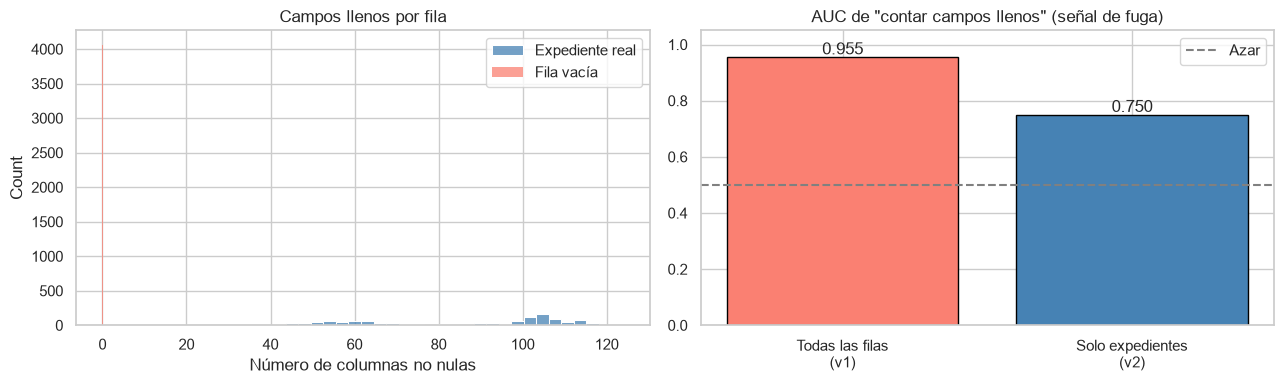


CONCLUSIÓN AUTOMÁTICA:
  Contar campos llenos predice la etiqueta v1 con AUC=0.95 en todas las filas, pero baja a 0.75 entre expedientes reales. Las métricas de la v1 están infladas por las filas vacías: la v1 se descarta como referencia.


In [4]:
# =============================================================================
# 0.1 AUDITORÍA: filas vacías y fuga de información en la v1
# =============================================================================
import unicodedata
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.model_selection import learning_curve as sk_learning_curve
from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_selection import f_classif as sk_f_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score

SEED = 42
# Copia de trabajo sin columnas duplicadas (no altera df_morge de secciones anteriores)
df_a3 = df_morge.loc[:, ~pd.Index(df_morge.columns).duplicated()].copy()
PLACEHOLDERS = {'', 'SIN DATO', 'SIN DATOS', 'NINGUNA', 'NINGUNO', 'NO', 'N A', 'NA', 'NAN', 'NONE',
                'NO PRESENTA', 'NO SE OBSERVAN', 'NO SE OBSERVA', 'S D', 'SD', 'SIN', 'NO APLICA',
                'NO VALORABLE', 'POR VALORAR', 'DESCONOCIDO', 'X', '0'}

def norm_txt(x):
    # Mayúsculas, sin acentos, sin signos, espacios simples
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return ''
    s = unicodedata.normalize('NFKD', str(x)).encode('ascii', 'ignore').decode()
    s = re.sub(r'[^A-Z0-9 ]', ' ', s.upper())
    return re.sub(r'\s+', ' ', s).strip()

def limpiar_texto(x):
    s = norm_txt(x)
    return '' if s in PLACEHOLDERS else s

def buscar_col(df, exacta, *claves):
    # Devuelve la columna exacta o la primera cuyo nombre normalizado contiene todas las claves
    if exacta in df.columns:
        return exacta
    for c in df.columns:
        n = norm_txt(c)
        if all(k in n for k in claves):
            return c
    raise KeyError(f'No se encontró la columna {claves}')

COL = {
    'anio':        buscar_col(df_a3, 'AÑO', 'ANO'),
    'status':      buscar_col(df_a3, 'STATUS', 'STATUS'),
    'tipo':        buscar_col(df_a3, 'TIPO\n (QUÉ INGRESA A SEMEFO)', 'TIPO', 'INGRESA'),
    'sexo':        buscar_col(df_a3, 'SEXO', 'SEXO'),
    'edad':        buscar_col(df_a3, 'EDAD', 'EDAD'),
    'estatura':    buscar_col(df_a3, 'ESTATURA EN CM.', 'ESTATURA'),
    'municipio':   buscar_col(df_a3, 'MUNICIPIO DE PROCEDENCIA', 'MUNICIPIO', 'PROCEDENCIA'),
    'ropa':        buscar_col(df_a3, 'DESCRIPCION DE ROPA QUE VESTIA', 'ROPA', 'VESTIA'),
    'senas':       buscar_col(df_a3, 'SEÑAS PARTICULARES Y/O CARACTERISTICAS \n(CICATRICES, TATUAJES, LUNARES, MANCHAS, ETC.)', 'SENAS', 'PARTICULARES'),
    'nombre_ident': buscar_col(df_a3, 'EN CASO DE ESTAR IDENTIFICADO, NOMBRE QUE CORRESPONDE AL CADAVER\nDEBERA ESTABLECER AQUÍ EL NOMBRE EN EL MOMENTO EN QUE SE ACTUALICE DICHA SITUACION', 'CASO', 'IDENTIFICADO', 'NOMBRE'),
}
print('Columnas utilizadas en el baseline:')
for k, v in COL.items():
    print(f'  {k:<13} -> {v!r}'[:110])

# --- Diagnóstico
fila_valida = df_a3[COL['status']].notna() | df_a3[COL['anio']].notna()
campos_llenos = df_a3.notna().sum(axis=1)
y_v1 = df_a3[COL['nombre_ident']].map(limpiar_texto).ne('').astype(int)   # etiqueta usada en la v1

print(f"\nFilas totales del archivo: {len(df_a3):,}")
print(f"Filas con expediente (STATUS o AÑO no nulos): {fila_valida.sum():,}")
print(f"Filas vacías / de formato: {(~fila_valida).sum():,}  ({(~fila_valida).mean():.1%})")
print(f"Mediana de campos llenos -> expedientes: {campos_llenos[fila_valida].median():.0f} | filas vacías: {campos_llenos[~fila_valida].median():.0f}")

display(pd.crosstab(np.where(fila_valida, 'Expediente real', 'Fila vacía'),
                    np.where(y_v1 == 1, 'IDENTIFICADO (v1)', 'NO IDENTIFICADO (v1)'),
                    margins=True, margins_name='Total'))

auc_todo = roc_auc_score(y_v1, campos_llenos)
auc_valido = roc_auc_score(y_v1[fila_valida], campos_llenos[fila_valida])
print(f"AUC de un 'modelo' que solo cuenta campos llenos -> todas las filas: {auc_todo:.3f} | solo expedientes: {auc_valido:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(campos_llenos[fila_valida], color='steelblue', label='Expediente real', ax=ax[0], bins=40)
sns.histplot(campos_llenos[~fila_valida], color='salmon', label='Fila vacía', ax=ax[0], bins=40)
ax[0].set_title('Campos llenos por fila'); ax[0].set_xlabel('Número de columnas no nulas'); ax[0].legend()
ax[1].bar(['Todas las filas\n(v1)', 'Solo expedientes\n(v2)'], [auc_todo, auc_valido], color=['salmon', 'steelblue'], edgecolor='black')
ax[1].axhline(0.5, ls='--', color='gray', label='Azar')
for i, v in enumerate([auc_todo, auc_valido]):
    ax[1].text(i, v + 0.01, f'{v:.3f}', ha='center')
ax[1].set_ylim(0, 1.05); ax[1].set_title('AUC de "contar campos llenos" (señal de fuga)'); ax[1].legend()
plt.tight_layout(); plt.show()

print('\nCONCLUSIÓN AUTOMÁTICA:')
if auc_todo - auc_valido > 0.05:
    print(f"  Contar campos llenos predice la etiqueta v1 con AUC={auc_todo:.2f} en todas las filas, pero baja a {auc_valido:.2f} "
          "entre expedientes reales. Las métricas de la v1 están infladas por las filas vacías: la v1 se descarta como referencia.")
else:
    print("  No se detecta inflación relevante por filas vacías.")

In [5]:
# =============================================================================
# 0.2 BASE LIMPIA (solo expedientes) + PSEUDO-FICHAS ANTE-MORTEM
# =============================================================================
from sklearn.model_selection import train_test_split

def parse_edad(x):
    if pd.isna(x): return np.nan
    s = str(x).upper().replace(',', '.')
    nums = [float(n) for n in re.findall(r'\d+(?:\.\d+)?', s)]
    if not nums: return np.nan
    if 'MES' in s:                      return nums[0] / 12
    if 'DIA' in s or 'SEMANA' in s:     return 0.0
    v = np.mean(nums[:2]) if len(nums) >= 2 and nums[1] < 120 else nums[0]   # rango "30-35" -> 32.5
    return v if 0 <= v <= 110 else np.nan

def parse_estatura(x):
    if pd.isna(x): return np.nan
    nums = re.findall(r'\d+(?:\.\d+)?', str(x).replace(',', '.'))
    if not nums: return np.nan
    v = float(nums[0])
    if v < 3: v *= 100                  # 1.65 m -> 165 cm
    return v if 40 <= v <= 220 else np.nan   # descarta capturas imposibles (p. ej. 7 cm)

def parse_sexo(x):
    s = norm_txt(x)
    if s.startswith(('MASC', 'HOMBRE')): return 'M'
    if s.startswith(('FEM', 'MUJER')):   return 'F'
    return 'ND'

exp = df_a3.loc[fila_valida]
bl = pd.DataFrame({
    'ID_INTERNO': exp.index.values,
    'SEXO':       exp[COL['sexo']].map(parse_sexo).values,
    'EDAD':       exp[COL['edad']].map(parse_edad).values,
    'ESTATURA':   exp[COL['estatura']].map(parse_estatura).values,
    'MUNICIPIO':  exp[COL['municipio']].map(limpiar_texto).values,
    'SENAS':      exp[COL['senas']].map(limpiar_texto).values,
    'ROPA':       exp[COL['ropa']].map(limpiar_texto).values,
    'TIPO':       exp[COL['tipo']].map(norm_txt).values,
})
status_n = exp[COL['status']].map(norm_txt)
nombre_ok = exp[COL['nombre_ident']].map(limpiar_texto).ne('')
# En la base el estatus positivo aparece como 'IDENTIFICADO NO RECLAMADO'; se toma cualquier estatus que inicie con IDENTIFICADO o con nombre registrado
bl['IDENTIFICADO'] = ((status_n.str.startswith('IDENTIFICADO')) | nombre_ok).astype(int).values

print(f"Expedientes en la base limpia: {len(bl):,}")
print(f"Identificados: {bl.IDENTIFICADO.sum():,} ({bl.IDENTIFICADO.mean():.1%}) | No identificados: {(1-bl.IDENTIFICADO).sum():,}")
print('\nConcordancia STATUS vs nombre registrado:')
display(pd.crosstab(status_n.values, nombre_ok.values, rownames=['STATUS'], colnames=['¿Tiene nombre?']))

cobertura = pd.DataFrame({
    c: bl.groupby('IDENTIFICADO')[c].apply(lambda s: (s.notna() & s.astype(str).ne('')).mean())
    for c in ['EDAD', 'ESTATURA', 'MUNICIPIO', 'SENAS', 'ROPA']
}).T.rename(columns={0: 'No identificados', 1: 'Identificados'})
print('\nCobertura de campos por clase (proporción con dato):')
display(cobertura.style.format('{:.1%}'))

# ---------------------------- Pseudo-fichas ----------------------------------
NIVELES_RUIDO = {
    'bajo':  dict(sd_edad=3, sd_est=3, p_falta_est=0.2, p_drop=0.3, p_typo=0.02, p_sin_ropa=0.2, p_mun=0.3, p_sexo=0.01),
    'medio': dict(sd_edad=5, sd_est=5, p_falta_est=0.4, p_drop=0.5, p_typo=0.05, p_sin_ropa=0.4, p_mun=0.5, p_sexo=0.02),
    'alto':  dict(sd_edad=8, sd_est=8, p_falta_est=0.6, p_drop=0.7, p_typo=0.10, p_sin_ropa=0.6, p_mun=0.7, p_sexo=0.05),
}
MUNICIPIOS = bl.loc[bl.MUNICIPIO.ne(''), 'MUNICIPIO'].unique()

def perturbar_texto(txt, p_drop, p_typo, rng):
    toks = txt.split()
    if not toks: return ''
    keep = [t for t in toks if rng.random() > p_drop] or [toks[rng.integers(len(toks))]]
    out = []
    for t in keep:
        if len(t) > 3 and rng.random() < p_typo:
            i = rng.integers(len(t)); t = t[:i] + chr(rng.integers(65, 91)) + t[i+1:]
        out.append(t)
    rng.shuffle(out)
    return ' '.join(out)

def generar_pseudofichas(src, nivel='medio', seed=SEED):
    p, rng = NIVELES_RUIDO[nivel], np.random.default_rng(seed)
    filas = []
    for _, r in src.iterrows():
        sexo = r.SEXO
        if sexo in ('M', 'F') and rng.random() < p['p_sexo']:
            sexo = 'F' if sexo == 'M' else 'M'
        edad = r.EDAD + rng.normal(0, p['sd_edad']) if pd.notna(r.EDAD) else np.nan
        est = np.nan if (pd.isna(r.ESTATURA) or rng.random() < p['p_falta_est']) else r.ESTATURA + rng.normal(0, p['sd_est'])
        mun = r.MUNICIPIO if (rng.random() >= p['p_mun'] or len(MUNICIPIOS) == 0) else rng.choice(MUNICIPIOS)
        filas.append(dict(QUERY_ID=int(r.ID_INTERNO), ID_VERDADERO=int(r.ID_INTERNO), SEXO=sexo, EDAD=edad, ESTATURA=est,
                          MUNICIPIO=mun, SENAS=perturbar_texto(r.SENAS, p['p_drop'], p['p_typo'], rng),
                          ROPA='' if rng.random() < p['p_sin_ropa'] else perturbar_texto(r.ROPA, p['p_drop'], p['p_typo'], rng)))
    return pd.DataFrame(filas)

ident = bl[bl.IDENTIFICADO == 1]
ids_train, ids_test = train_test_split(ident.ID_INTERNO.values, test_size=0.30, random_state=SEED)
Q_train = generar_pseudofichas(ident[ident.ID_INTERNO.isin(ids_train)], 'medio', seed=SEED)
Q_test  = generar_pseudofichas(ident[ident.ID_INTERNO.isin(ids_test)],  'medio', seed=SEED + 1)
print(f"\nPseudo-fichas -> entrenamiento: {len(Q_train)} | prueba: {len(Q_test)} | índice de búsqueda (libro completo): {len(bl):,} expedientes")
# El texto libre de señas y ropa proviene de expedientes reales y puede arrastrar nombres de terceros:
# se enmascara antes de mostrarlo (mismo criterio que ver_muestra() en el notebook post-mortem).
# El enmascarado conserva lo que ilustra el ejemplo —cuántas palabras sobreviven, de qué longitud y en
# qué orden tras la perturbación— sin revelar el contenido.
def enmascarar(txt, max_tokens=12):
    toks = str(txt).split()
    if not toks:
        return '(vacío)'
    vis = ' '.join(t[0] + '•' * (len(t) - 1) for t in toks[:max_tokens])
    return vis + (f' … (+{len(toks) - max_tokens} palabras)' if len(toks) > max_tokens else '')

def _redondear(v):
    return round(v, 1) if pd.notna(v) else v

print("Ejemplo de transformación (campos no identificantes; texto libre enmascarado):")
_ej = ident[ident.ID_INTERNO == Q_test.ID_VERDADERO.iloc[0]].iloc[0]
_q0 = Q_test.iloc[0]
display(pd.DataFrame(
    {'Expediente (post-mortem)': [_ej.SEXO, _redondear(_ej.EDAD), _redondear(_ej.ESTATURA),
                                  enmascarar(_ej.SENAS), enmascarar(_ej.ROPA)],
     'Pseudo-ficha (ante-mortem)': [_q0.SEXO, _redondear(_q0.EDAD), _redondear(_q0.ESTATURA),
                                    enmascarar(_q0.SENAS), enmascarar(_q0.ROPA)]},
    index=['Sexo', 'Edad', 'Estatura', 'Señas (enmascarada)', 'Ropa (enmascarada)']))

Expedientes en la base limpia: 1,247


Identificados: 355 (28.5%) | No identificados: 892

Concordancia STATUS vs nombre registrado:


¿Tiene nombre?,False,True
STATUS,,
IDENTIFICADO NO RECLAMADO,2,352
NO IDENTIFICADO,892,1



Cobertura de campos por clase (proporción con dato):


IDENTIFICADO,No identificados,Identificados
EDAD,87.2%,94.1%
ESTATURA,48.8%,61.1%
MUNICIPIO,96.9%,99.2%
SENAS,63.5%,69.6%
ROPA,71.3%,81.7%



Pseudo-fichas -> entrenamiento: 248 | prueba: 107 | índice de búsqueda (libro completo): 1,247 expedientes
Ejemplo de transformación (campos no identificantes; texto libre enmascarado):


,Expediente (post-mortem),Pseudo-ficha (ante-mortem)
Sexo,M,M
Edad,42.5,45.9
Estatura,NaN,NaN
Señas (enmascarada),M•••••••• C••••••••• H•••••••••••• E• R••••• O...,H•••••••••••• M••••••••
Ropa (enmascarada),C••••• D• M•••• L•••• E• C•••••• V••• N•••• B•...,(vacío)


In [6]:
# =============================================================================
# 0.3 FUNCIONES DE EVALUACIÓN (Recall@k, MRR, PR-AUC)
# =============================================================================
KS = (1, 5, 10, 20)

def rangos_verdaderos(pares, score_col, query_ids):
    # Rango (1 = primero) del expediente correcto para cada ficha. Empates: criterio pesimista.
    # Si el blocking eliminó al candidato correcto, rango = inf (cuenta como fallo).
    rangos = {}
    for qid, g in pares.groupby('QUERY_ID', sort=False):
        s = g[score_col].values; y = g['y'].values
        if y.sum() == 0:
            rangos[qid] = np.inf; continue
        st = s[y == 1][0]
        rangos[qid] = 1 + int(np.sum(s[y == 0] >= st))
    return np.array([rangos.get(q, np.inf) for q in query_ids], dtype=float)

def metricas_ranking(rangos, ks=KS):
    out = {f'Recall@{k}': float(np.mean(rangos <= k)) for k in ks}
    out['MRR'] = float(np.mean(np.where(np.isfinite(rangos), 1.0 / rangos, 0.0)))
    return out

def metricas_pares(y, score):
    return {'PR-AUC (pares)': average_precision_score(y, score), 'ROC-AUC (pares)': roc_auc_score(y, score)}

print("Funciones de evaluación definidas: Recall@k", KS, "+ MRR + PR-AUC/ROC-AUC a nivel par.")

Funciones de evaluación definidas: Recall@k (1, 5, 10, 20) + MRR + PR-AUC/ROC-AUC a nivel par.


In [7]:
# =============================================================================
# 0.4 VECTORIZACIÓN DEL ÍNDICE Y CONSTRUCCIÓN DE PARES (con blocking)
# =============================================================================
tfidf_senas = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2, sublinear_tf=True)
tfidf_ropa  = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2, sublinear_tf=True)
XS_idx = tfidf_senas.fit_transform(bl.SENAS)
XR_idx = tfidf_ropa.fit_transform(bl.ROPA)

MARCAS = ['TATUA', 'CICATRI', 'LUNAR', 'PERFORA', 'PIERCING', 'MANCHA', 'AMPUTA', 'QUEMAD', 'VERRUG']
def matriz_marcas(textos):
    return np.array([[int(m in t) for m in MARCAS] for t in textos], dtype=float)
M_idx = matriz_marcas(bl.SENAS)

SEXO_idx, EDAD_idx, EST_idx = bl.SEXO.values, bl.EDAD.values.astype(float), bl.ESTATURA.values.astype(float)
MUN_idx, ID_idx, SENAS_VACIA_idx = bl.MUNICIPIO.values, bl.ID_INTERNO.values, bl.SENAS.eq('').values

FEATS = ['dif_edad', 'falta_edad', 'dif_estatura', 'falta_estatura', 'sexo_coincide',
         'municipio_coincide', 'sim_senas', 'sim_ropa', 'marcas_comunes', 'senas_vacia_exp', 'senas_vacia_ficha']
EDAD_MAX_BLOCK, IMPUT_DIF = 15, 20.0

def construir_pares(Q, usar_blocking=True):
    sim_s = (tfidf_senas.transform(Q.SENAS) @ XS_idx.T).toarray()
    sim_r = (tfidf_ropa.transform(Q.ROPA) @ XR_idx.T).toarray()
    marcas = matriz_marcas(Q.SENAS) @ M_idx.T
    bloques = []
    for i, q in enumerate(Q.itertuples(index=False)):
        d_edad = np.abs(EDAD_idx - q.EDAD) if pd.notna(q.EDAD) else np.full(len(bl), np.nan)
        d_est  = np.abs(EST_idx - q.ESTATURA) if pd.notna(q.ESTATURA) else np.full(len(bl), np.nan)
        mask = np.ones(len(bl), bool)
        if usar_blocking:
            if q.SEXO != 'ND':
                mask &= (SEXO_idx == q.SEXO) | (SEXO_idx == 'ND')
            mask &= np.isnan(d_edad) | (d_edad <= EDAD_MAX_BLOCK)
        idx = np.where(mask)[0]
        bloques.append(pd.DataFrame({
            'QUERY_ID': q.QUERY_ID, 'ID_CAND': ID_idx[idx],
            'y': (ID_idx[idx] == q.ID_VERDADERO).astype(int),
            'dif_edad': np.nan_to_num(d_edad[idx], nan=IMPUT_DIF), 'falta_edad': np.isnan(d_edad[idx]).astype(int),
            'dif_estatura': np.nan_to_num(d_est[idx], nan=IMPUT_DIF), 'falta_estatura': np.isnan(d_est[idx]).astype(int),
            'sexo_coincide': ((SEXO_idx[idx] == q.SEXO) & (q.SEXO != 'ND')).astype(int),
            'municipio_coincide': ((MUN_idx[idx] == q.MUNICIPIO) & (q.MUNICIPIO != '')).astype(int),
            'sim_senas': sim_s[i, idx], 'sim_ropa': sim_r[i, idx], 'marcas_comunes': marcas[i, idx],
            'senas_vacia_exp': SENAS_VACIA_idx[idx].astype(int),
            'senas_vacia_ficha': np.full(len(idx), int(q.SENAS == '')),
        }))
    return pd.concat(bloques, ignore_index=True)

P_train = construir_pares(Q_train)
P_test  = construir_pares(Q_test)

pc_train = P_train.groupby('QUERY_ID').y.max().reindex(Q_train.QUERY_ID).fillna(0).mean()
pc_test  = P_test.groupby('QUERY_ID').y.max().reindex(Q_test.QUERY_ID).fillna(0).mean()
rr = 1 - len(P_test) / (len(Q_test) * len(bl))
print(f"Pares de entrenamiento: {len(P_train):,} (positivos: {P_train.y.sum()}, prevalencia {P_train.y.mean():.3%})")
print(f"Pares de prueba:        {len(P_test):,} (positivos: {P_test.y.sum()}, prevalencia {P_test.y.mean():.3%})")
print(f"Blocking -> pair completeness train/test: {pc_train:.1%} / {pc_test:.1%} | reduction ratio: {rr:.1%}")
print(f"Candidatos promedio por ficha tras blocking: {len(P_test)/len(Q_test):.0f} de {len(bl):,}")
display(P_train.groupby('y')[FEATS].mean().T.rename(columns={0: 'Media pares NO coincidentes', 1: 'Media pares coincidentes'}).round(3))

Pares de entrenamiento: 147,300 (positivos: 238, prevalencia 0.162%)
Pares de prueba:        64,008 (positivos: 105, prevalencia 0.164%)
Blocking -> pair completeness train/test: 96.0% / 98.1% | reduction ratio: 52.0%
Candidatos promedio por ficha tras blocking: 598 de 1,247


y,Media pares NO coincidentes,Media pares coincidentes
dif_edad,10.596,4.712
falta_edad,0.274,0.055
dif_estatura,18.671,14.848
falta_estatura,0.834,0.672
sexo_coincide,0.918,0.992
municipio_coincide,0.276,0.559
sim_senas,0.043,0.499
sim_ropa,0.051,0.398
marcas_comunes,0.102,0.370
senas_vacia_exp,0.347,0.324


Selección preliminar de hiperparámetros de la regresión logística (GroupKFold=5):


,C,class_weight,Recall@10 (CV),MRR (CV)
0,0.01,balanced,0.851,0.760
1,0.01,None,0.851,0.775
2,0.10,balanced,0.851,0.758
3,0.10,None,0.847,0.764
4,1.00,balanced,0.851,0.758
5,1.00,None,0.838,0.758


Configuración elegida: {'C': 0.01, 'class_weight': None}
Recall@10 teórico del azar (10 / candidatos por ficha): 0.026

Pisos de referencia y regresión logística sobre el conjunto de prueba (ruido medio):


,Recall@1,Recall@5,Recall@10,Recall@20,MRR,PR-AUC (pares),ROC-AUC (pares)
Modelo,,,,,,,
Azar (piso),0.000,0.009,0.028,0.047,0.014,0.002,0.449
Heurística TF-IDF (piso),0.766,0.841,0.850,0.869,0.801,0.521,0.941
Regresión logística,0.766,0.841,0.879,0.925,0.803,0.575,0.987


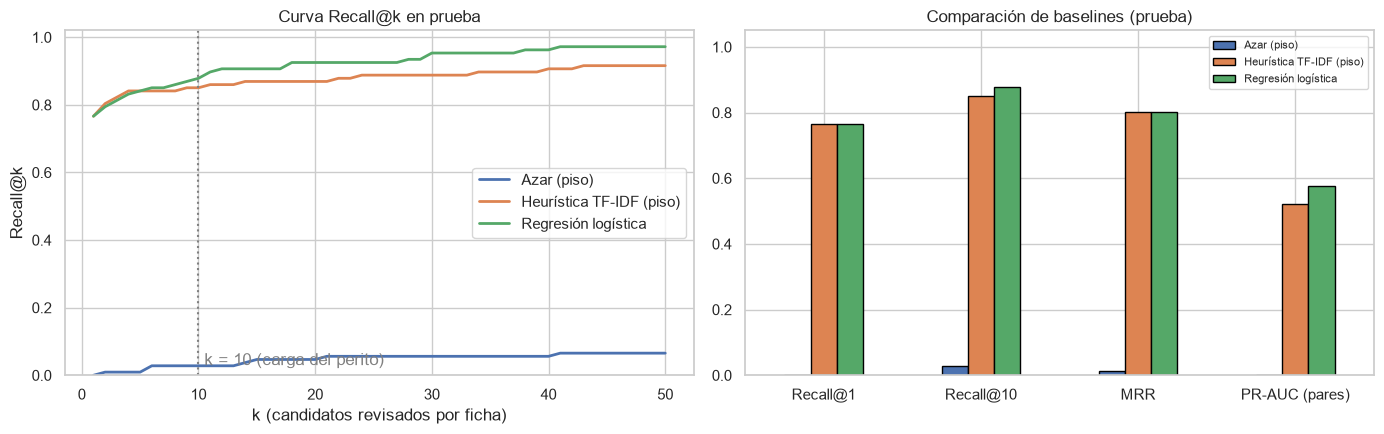

In [8]:
# =============================================================================
# 0.5 ENTRENAMIENTO Y EVALUACIÓN DE B0, B1, B2
# =============================================================================
def score_b1(P):
    cerc_edad = 1 - np.minimum(P.dif_edad, IMPUT_DIF) / IMPUT_DIF
    cerc_est  = 1 - np.minimum(P.dif_estatura, IMPUT_DIF) / IMPUT_DIF
    return 0.35*P.sim_senas + 0.25*P.sim_ropa + 0.20*cerc_edad*(1-P.falta_edad) + 0.10*cerc_est*(1-P.falta_estatura) + 0.10*P.municipio_coincide

B2_PARAMS = {'C': 1.0, 'class_weight': 'balanced'}
def nuevo_b2():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=SEED, **B2_PARAMS))

# ---- Selección ligera de hiperparámetros por validación cruzada agrupada por ficha (solo datos de entrenamiento)
def cv_ranking(feats, params, n_splits=5):
    r10, mrr = [], []
    for tr_i, va_i in GroupKFold(n_splits=n_splits).split(P_train, P_train.y, groups=P_train.QUERY_ID):
        Ptr, Pva = P_train.iloc[tr_i], P_train.iloc[va_i].copy()
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=SEED, **params)).fit(Ptr[feats], Ptr.y)
        Pva['s'] = m.predict_proba(Pva[feats])[:, 1]
        mr = metricas_ranking(rangos_verdaderos(Pva, 's', Pva.QUERY_ID.unique()))
        r10.append(mr['Recall@10']); mrr.append(mr['MRR'])
    return np.mean(r10), np.mean(mrr)
grid = [{'C': c, 'class_weight': cw} for c in (0.01, 0.1, 1.0) for cw in ('balanced', None)]
tabla_grid = pd.DataFrame([{**p, 'class_weight': str(p['class_weight']), **dict(zip(['Recall@10 (CV)', 'MRR (CV)'], cv_ranking(FEATS, p)))} for p in grid])
mejor = tabla_grid.sort_values(['Recall@10 (CV)', 'MRR (CV)'], ascending=False).iloc[0]
B2_PARAMS = {'C': float(mejor['C']), 'class_weight': None if mejor['class_weight'] == 'None' else 'balanced'}
print('Selección preliminar de hiperparámetros de la regresión logística (GroupKFold=5):')
display(tabla_grid.round(3))
print(f"Configuración elegida: {B2_PARAMS}")

rng_b0 = np.random.default_rng(SEED)
for P in (P_train, P_test):
    P['s_B0'] = rng_b0.random(len(P))
    P['s_B1'] = score_b1(P)

b2 = nuevo_b2().fit(P_train[FEATS], P_train.y)
P_train['s_B2'] = b2.predict_proba(P_train[FEATS])[:, 1]
P_test['s_B2']  = b2.predict_proba(P_test[FEATS])[:, 1]

filas, RANGOS_TEST = [], {}
for nombre, col in [('Azar (piso)', 's_B0'), ('Heurística TF-IDF (piso)', 's_B1'), ('Regresión logística', 's_B2')]:
    r_test = rangos_verdaderos(P_test, col, Q_test.QUERY_ID.values)
    RANGOS_TEST[nombre] = r_test
    filas.append({'Modelo': nombre, **metricas_ranking(r_test), **metricas_pares(P_test.y, P_test[col])})
res_baselines = pd.DataFrame(filas).set_index('Modelo')
rand_r10 = float(np.mean(np.minimum(10, P_test.groupby('QUERY_ID').size()) / P_test.groupby('QUERY_ID').size()))
print(f"Recall@10 teórico del azar (10 / candidatos por ficha): {rand_r10:.3f}")
print("\nPisos de referencia y regresión logística sobre el conjunto de prueba (ruido medio):")
display(res_baselines.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ks_plot = np.arange(1, 51)
for nombre, r in RANGOS_TEST.items():
    ax[0].plot(ks_plot, [np.mean(r <= k) for k in ks_plot], lw=2, label=nombre)
ax[0].axvline(10, ls=':', color='gray'); ax[0].text(10.5, 0.03, 'k = 10 (carga del perito)', color='gray')
ax[0].set_xlabel('k (candidatos revisados por ficha)'); ax[0].set_ylabel('Recall@k'); ax[0].set_title('Curva Recall@k en prueba'); ax[0].legend(); ax[0].set_ylim(0, 1.02)
res_baselines[['Recall@1', 'Recall@10', 'MRR', 'PR-AUC (pares)']].T.plot(kind='bar', ax=ax[1], edgecolor='black', rot=0)
ax[1].set_title('Comparación de baselines (prueba)'); ax[1].set_ylim(0, 1.05); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

,Inf. mutua (filtro),F ANOVA (filtro),Coef. estandarizado (embebido),Odds ratio x1 DE,C de entrada L1 (menor = más útil),Δ Recall@10 al quitarla (wrapper),Δ PR-AUC al quitarla (wrapper),Permutación Δ PR-AUC,Ranking promedio
sim_senas,0.0184,4733.5708,0.8036,2.2335,0.0001,0.2097,0.3104,0.4743,1.00
sim_ropa,0.0130,1960.6114,0.5225,1.6862,0.0001,0.1129,0.0870,0.1836,2.00
dif_edad,0.0035,119.6131,-0.3514,0.7037,0.0003,0.0323,0.0261,0.0437,4.75
senas_vacia_ficha,0.0000,1.3079,0.5166,1.6763,0.0001,0.0000,0.0565,0.0805,5.00
dif_estatura,0.0046,59.2309,-0.1937,0.8239,0.0008,0.0161,0.0105,0.0260,5.50
senas_vacia_exp,0.0000,2.5817,0.4978,1.6451,0.0003,0.0000,0.0396,0.0638,5.50
municipio_coincide,0.0009,64.2531,0.2231,1.2499,0.0003,0.0161,0.0045,0.0111,6.50
marcas_comunes,0.0013,134.3782,-0.0583,0.9434,0.0008,0.0000,-0.0024,0.0041,7.75
falta_estatura,0.0004,27.1355,-0.0239,0.9764,0.0066,0.0000,0.0044,0.0034,8.75
falta_edad,0.0009,42.3031,-0.0558,0.9458,0.0066,0.0000,-0.0034,0.0020,9.25


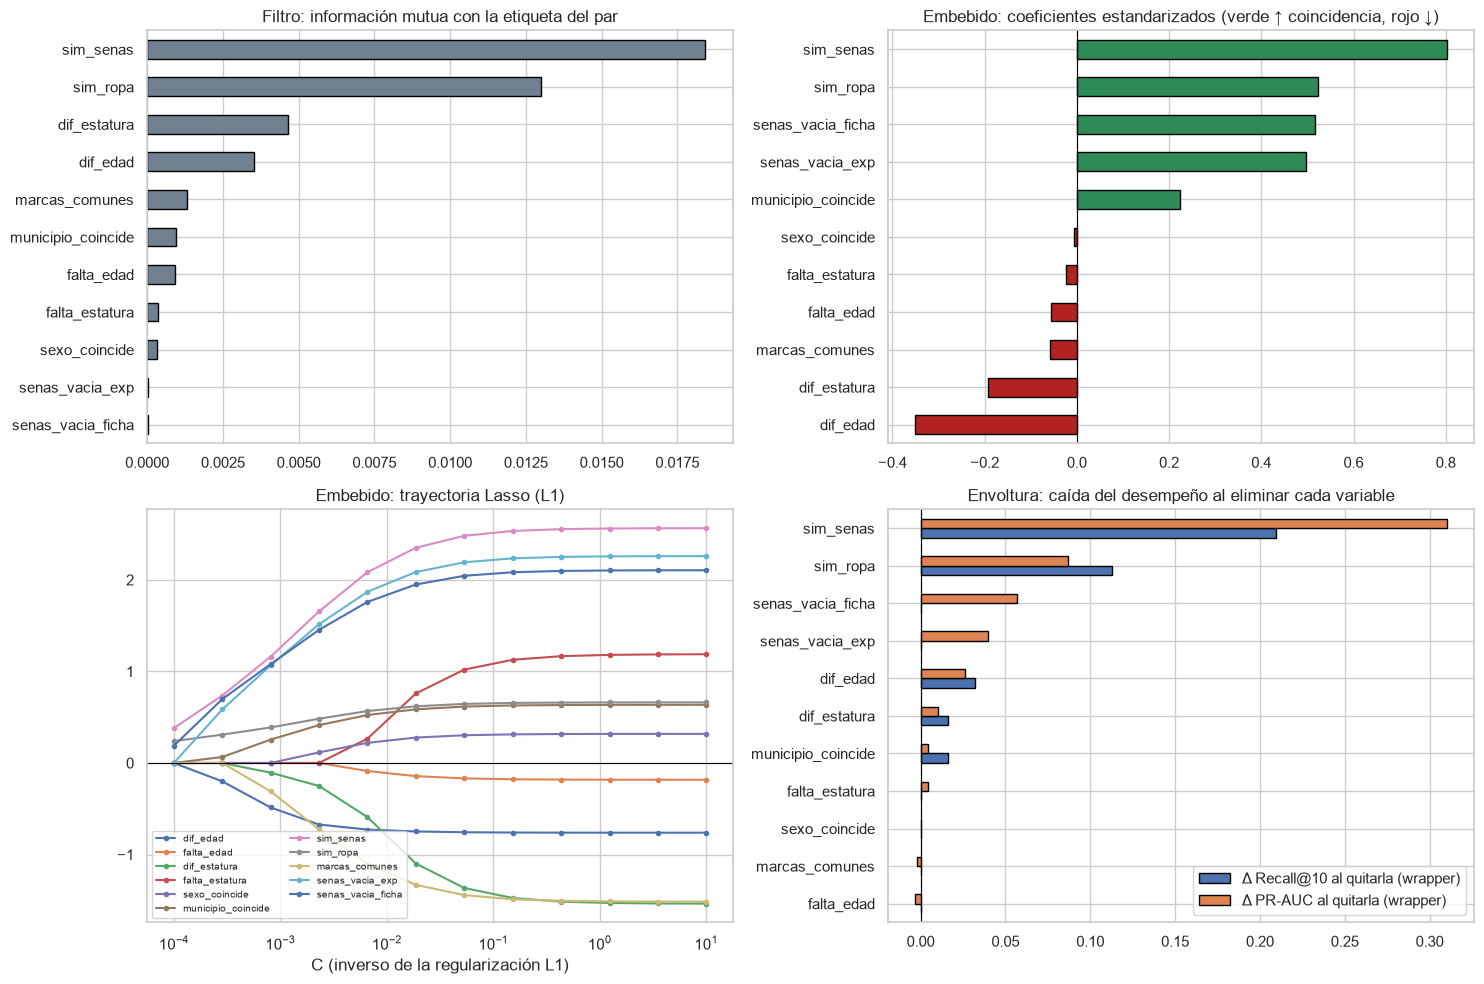


CONCLUSIÓN AUTOMÁTICA (selección de características):
  Top-3 por consenso de métodos: ['sim_senas', 'sim_ropa', 'dif_edad']
  Candidatas a eliminar (no aportan en ablación ni permutación): ['sexo_coincide']
  Conjunto final (10 variables): ['dif_edad', 'falta_edad', 'dif_estatura', 'falta_estatura', 'municipio_coincide', 'sim_senas', 'sim_ropa', 'marcas_comunes', 'senas_vacia_exp', 'senas_vacia_ficha']
  Validación -> completo: Recall@10=0.903, PR-AUC=0.501 | seleccionado: Recall@10=0.903, PR-AUC=0.501


In [9]:
# =============================================================================
# 0.6 IMPORTANCIA Y SELECCIÓN DE CARACTERÍSTICAS
# =============================================================================
q_fit, q_val = train_test_split(Q_train.QUERY_ID.values, test_size=0.25, random_state=SEED)
P_fit, P_val = P_train[P_train.QUERY_ID.isin(q_fit)], P_train[P_train.QUERY_ID.isin(q_val)]

def recall10_val(feats):
    m = nuevo_b2().fit(P_fit[feats], P_fit.y)
    Pv = P_val.assign(s=m.predict_proba(P_val[feats])[:, 1])
    return metricas_ranking(rangos_verdaderos(Pv, 's', q_val))['Recall@10'], average_precision_score(Pv.y, Pv.s), m

# ---- 1) FILTRO
rng_mi = np.random.default_rng(SEED)
neg_idx = P_fit.index[P_fit.y == 0]
sub = P_fit.loc[np.r_[P_fit.index[P_fit.y == 1], rng_mi.choice(neg_idx, min(30000, len(neg_idx)), replace=False)]]
mi = mutual_info_classif(sub[FEATS], sub.y, discrete_features=[f in ('falta_edad','falta_estatura','sexo_coincide','municipio_coincide','senas_vacia_exp','senas_vacia_ficha') for f in FEATS], random_state=SEED)
F_vals, p_vals = sk_f_classif(P_fit[FEATS], P_fit.y)

# ---- 2) EMBEBIDO: coeficientes estandarizados + trayectoria L1
r10_full, ap_full, m_full = recall10_val(FEATS)
coefs = pd.Series(m_full[-1].coef_[0], index=FEATS)
Cs = np.logspace(-4, 1, 12)
Xs_fit = StandardScaler().fit_transform(P_fit[FEATS])
trayectoria = pd.DataFrame([LogisticRegression(penalty='l1', solver='liblinear', C=c, class_weight='balanced', random_state=SEED)
                            .fit(Xs_fit, P_fit.y).coef_[0] for c in Cs], index=Cs, columns=FEATS)
primer_C_activo = {f: (trayectoria.index[trayectoria[f].abs() > 1e-6].min() if (trayectoria[f].abs() > 1e-6).any() else np.inf) for f in FEATS}

# ---- 3) ENVOLTURA: ablación + permutación
abl = {}
for f in FEATS:
    r10_sin, ap_sin, _ = recall10_val([x for x in FEATS if x != f])
    abl[f] = (r10_full - r10_sin, ap_full - ap_sin)
perm = permutation_importance(m_full, P_val[FEATS], P_val.y, scoring='average_precision', n_repeats=5, random_state=SEED, n_jobs=-1)

imp = pd.DataFrame({
    'Inf. mutua (filtro)': mi, 'F ANOVA (filtro)': F_vals,
    'Coef. estandarizado (embebido)': coefs.values, 'Odds ratio x1 DE': np.exp(coefs.values),
    'C de entrada L1 (menor = más útil)': [primer_C_activo[f] for f in FEATS],
    'Δ Recall@10 al quitarla (wrapper)': [abl[f][0] for f in FEATS], 'Δ PR-AUC al quitarla (wrapper)': [abl[f][1] for f in FEATS],
    'Permutación Δ PR-AUC': perm.importances_mean}, index=FEATS)
imp['Ranking promedio'] = pd.concat([imp['Inf. mutua (filtro)'].rank(ascending=False), imp['Coef. estandarizado (embebido)'].abs().rank(ascending=False),
                                     imp['Δ PR-AUC al quitarla (wrapper)'].rank(ascending=False), imp['Permutación Δ PR-AUC'].rank(ascending=False)], axis=1).mean(axis=1)
imp = imp.sort_values('Ranking promedio')
display(imp.round(4))

# ---- Visualización
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
imp['Inf. mutua (filtro)'].sort_values().plot(kind='barh', ax=axes[0, 0], color='slategray', edgecolor='black')
axes[0, 0].set_title('Filtro: información mutua con la etiqueta del par')
c_ord = imp['Coef. estandarizado (embebido)'].sort_values()
c_ord.plot(kind='barh', ax=axes[0, 1], color=['firebrick' if v < 0 else 'seagreen' for v in c_ord], edgecolor='black')
axes[0, 1].axvline(0, color='black', lw=0.8); axes[0, 1].set_title('Embebido: coeficientes estandarizados (verde ↑ coincidencia, rojo ↓)')
for f in FEATS:
    axes[1, 0].plot(trayectoria.index, trayectoria[f], marker='.', label=f)
axes[1, 0].set_xscale('log'); axes[1, 0].axhline(0, color='black', lw=0.8)
axes[1, 0].set_xlabel('C (inverso de la regularización L1)'); axes[1, 0].set_title('Embebido: trayectoria Lasso (L1)'); axes[1, 0].legend(fontsize=7, ncol=2)
imp[['Δ Recall@10 al quitarla (wrapper)', 'Δ PR-AUC al quitarla (wrapper)']].sort_values('Δ PR-AUC al quitarla (wrapper)').plot(kind='barh', ax=axes[1, 1], edgecolor='black')
axes[1, 1].axvline(0, color='black', lw=0.8); axes[1, 1].set_title('Envoltura: caída del desempeño al eliminar cada variable')
plt.tight_layout(); plt.show()

# ---- Decisión de selección (regla explícita y parsimoniosa)
descartables = [f for f in FEATS if abl[f][0] <= 0 and abl[f][1] <= 0.001 and perm.importances_mean[FEATS.index(f)] <= 0.001]
FEATS_SEL = [f for f in FEATS if f not in descartables] if descartables else FEATS.copy()
r10_sel, ap_sel, _ = recall10_val(FEATS_SEL)
if r10_sel < r10_full - 0.01:          # si la reducción empeora más de 1 pp, se conserva el conjunto completo
    FEATS_SEL, r10_sel, ap_sel = FEATS.copy(), r10_full, ap_full
print('\nCONCLUSIÓN AUTOMÁTICA (selección de características):')
print(f"  Top-3 por consenso de métodos: {list(imp.index[:3])}")
print(f"  Candidatas a eliminar (no aportan en ablación ni permutación): {descartables or 'ninguna'}")
print(f"  Conjunto final ({len(FEATS_SEL)} variables): {FEATS_SEL}")
print(f"  Validación -> completo: Recall@10={r10_full:.3f}, PR-AUC={ap_full:.3f} | seleccionado: Recall@10={r10_sel:.3f}, PR-AUC={ap_sel:.3f}")

In [10]:
# =============================================================================
# 0.7 REGRESIÓN LOGÍSTICA sobre FEATS_SEL — es el octavo modelo de la tabla comparativa de 4.4. Se miden sus tiempos de entrenamiento e inferencia
# para que entre en la comparativa en igualdad de condiciones con los demás modelos.
# =============================================================================
t0 = time.perf_counter()
b2_final = nuevo_b2().fit(P_train[FEATS_SEL], P_train.y)
t_fit_logreg = time.perf_counter() - t0

t0 = time.perf_counter()
P_test['s_B2F'] = b2_final.predict_proba(P_test[FEATS_SEL])[:, 1]
t_inf_logreg = (time.perf_counter() - t0) / len(Q_test) * 1000
P_train['s_B2F'] = b2_final.predict_proba(P_train[FEATS_SEL])[:, 1]

_r10_lr = metricas_ranking(rangos_verdaderos(P_test, 's_B2F', Q_test.QUERY_ID.values))['Recall@10']
print(f"Regresión logística -> Recall@10 = {_r10_lr:.3f} | "
      f"entrenamiento = {t_fit_logreg:.3f} s | inferencia = {t_inf_logreg:.3f} ms/ficha")

Regresión logística -> Recall@10 = 0.869 | entrenamiento = 0.041 s | inferencia = 0.021 ms/ficha


## 4.1 Contrato de datos

Verificación de que la preparación produjo los objetos esperados. Si algún valor no coincide, la comparativa entre
modelos no es válida y la ejecución se detiene.

In [11]:
# =============================================================================
# 4.1 CONTRATO DE DATOS — falla ruidosamente si la preparación no produjo los objetos esperados
# =============================================================================
errores = []

def _check(nombre, cond, detalle):
    if not cond:
        errores.append(f"  ✗ {nombre}: {detalle}")
    else:
        print(f"  ✓ {nombre}")

_check('len(df_a3) == 5317', len(df_a3) == 5317, f"obtenido {len(df_a3)}")
_check('fila_valida.sum() == 1247', fila_valida.sum() == 1247, f"obtenido {fila_valida.sum()}")
_check('bl.IDENTIFICADO.sum() == 355', bl.IDENTIFICADO.sum() == 355, f"obtenido {bl.IDENTIFICADO.sum()}")
_check('len(Q_train) == 248 and len(Q_test) == 107', len(Q_train) == 248 and len(Q_test) == 107,
       f"obtenido Q_train={len(Q_train)}, Q_test={len(Q_test)}")
_check('len(P_train) == 147_300 and len(P_test) == 64_008', len(P_train) == 147_300 and len(P_test) == 64_008,
       f"obtenido P_train={len(P_train):,}, P_test={len(P_test):,}")
_check('P_train.y.sum() == 238 and P_test.y.sum() == 105', P_train.y.sum() == 238 and P_test.y.sum() == 105,
       f"obtenido P_train.y.sum()={P_train.y.sum()}, P_test.y.sum()={P_test.y.sum()}")
_check('len(FEATS) == 11 and len(FEATS_SEL) == 10', len(FEATS) == 11 and len(FEATS_SEL) == 10,
       f"obtenido len(FEATS)={len(FEATS)}, len(FEATS_SEL)={len(FEATS_SEL)}")

if errores:
    print("\nCONTRATO DE DATOS VIOLADO:")
    print('\n'.join(errores))
    raise AssertionError(
        "El contrato de datos no se cumple. "
        "NO se debe ajustar el valor esperado: diagnosticar la causa (p. ej. una diferencia de "
        "comportamiento entre versiones de pandas/numpy) y corregirla para recuperar el comportamiento original."
    )
else:
    print("\nCONTRATO DE DATOS: OK — datos, pseudo-fichas, pares y características son los esperados.")
    print(f"Conjunto de características seleccionado (FEATS_SEL, {len(FEATS_SEL)} de {len(FEATS)}): {FEATS_SEL}")


  ✓ len(df_a3) == 5317
  ✓ fila_valida.sum() == 1247
  ✓ bl.IDENTIFICADO.sum() == 355
  ✓ len(Q_train) == 248 and len(Q_test) == 107
  ✓ len(P_train) == 147_300 and len(P_test) == 64_008
  ✓ P_train.y.sum() == 238 and P_test.y.sum() == 105
  ✓ len(FEATS) == 11 and len(FEATS_SEL) == 10

CONTRATO DE DATOS: OK — datos, pseudo-fichas, pares y características son los esperados.
Conjunto de características seleccionado (FEATS_SEL, 10 de 11): ['dif_edad', 'falta_edad', 'dif_estatura', 'falta_estatura', 'municipio_coincide', 'sim_senas', 'sim_ropa', 'marcas_comunes', 'senas_vacia_exp', 'senas_vacia_ficha']


## 4.2 Protocolo experimental común

Cinco reglas fijas para que las métricas sean comparables entre modelos:

1. **Todos los modelos son puntuadores de pares.** Reciben `P[FEATS_SEL]` (10 características: diferencias de edad
   y estatura, indicadores de dato faltante, coincidencia de sexo y municipio, similitud de señas y ropa, marcas
   comunes) y devuelven un score por par. `rangos_verdaderos` lo convierte en un ranking por ficha.
2. **La evaluación se hace siempre sobre el conjunto de prueba completo** (64,008 pares, 107 fichas), aunque el
   ajuste de un modelo use submuestra de negativos.
3. **Los modelos sin `predict_proba`** (`LinearSVC`) usan `decision_function`. Para ordenar basta que el score sea
   monótono; la calibración solo importa si ese número se le muestra al perito como "confianza" (ver 4.6).
4. **Escalado:** `make_pipeline(StandardScaler(), modelo)`, salvo el árbol de decisión, invariante a escala.
5. **Tiempos medidos** con `time.perf_counter()`: entrenamiento sobre `P_train` (147,300 pares) e inferencia por
   ficha sobre `P_test`.

**Desbalance.** La prevalencia de pares positivos es 0.162 % (238 de 147,300). Se usa `class_weight='balanced'` en
los estimadores que lo soportan y `sample_weight` balanceado en los que aceptan pesos por muestra. Al ser un
problema de ranking, lo determinante es el orden relativo de los scores dentro de cada ficha, no la probabilidad
absoluta.

## 4.3 Modelos individuales

Ocho modelos entrenados sobre `P_train[FEATS_SEL]` completo (147,300 pares) y evaluados sobre `P_test[FEATS_SEL]`
completo (64,008 pares). Siete se entrenan en la celda siguiente; el octavo —la regresión logística— se entrenó
en la sección 0.7, con los mismos datos, las mismas características y los mismos tiempos medidos.

| Modelo | Familia | Característica relevante |
|---|---|---|
| Regresión logística | Lineal probabilístico | Coeficientes interpretables como odds ratios; salida calibrada |
| Árbol de decisión (CART) | Reglas | Jerarquía de cortes inspeccionable; invariante a escala |
| k-NN | Instancias | Sin parámetros explícitos; el costo se traslada a la inferencia |
| Naive Bayes gaussiano | Generativo | Asume independencia condicional: el supuesto del modelo clásico de Fellegi y Sunter (1969) |
| SVM lineal | Margen máximo | Sin `predict_proba`; se usa `decision_function` |
| SVM de kernel RBF | Kernel | `Nystroem` + `LinearSVC`, para evitar el costo *O(n²)* del kernel exacto |
| Perceptrón multicapa (MLP) | Red neuronal | Única familia con tasa de aprendizaje, activación y arquitectura |
| LDA | Discriminante lineal | Asume covarianzas iguales entre clases y distribución gaussiana |

**Sin modelos de ensamble.** Por decisión del equipo se excluyen Random Forest, Gradient Boosting, Bagging, Voting
y Stacking: con una prevalencia de positivos de 0.16 %, un ensamble de alta capacidad puede introducir ruido
difícil de diagnosticar en lugar de aportar señal.

Como nota al pie se reporta un `SVC(kernel='rbf')` exacto sobre submuestra estratificada, excluido de la tabla
principal por no usar el mismo conjunto de entrenamiento que los demás.

In [12]:
# =============================================================================
# 4.3 ENTRENAMIENTO DE LOS MODELOS INDIVIDUALES
# =============================================================================
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC, SVC
from sklearn.kernel_approximation import Nystroem
from sklearn.neural_network import MLPClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

def entrenar_evaluar(nombre, pipeline, feats=FEATS_SEL, fit_params=None, escalado=True):
    """Ajusta sobre P_train completo, evalúa sobre P_test completo (regla 2 del protocolo).
    Mide tiempo de entrenamiento y tiempo de inferencia por ficha (regla 5)."""
    fit_params = fit_params or {}
    t0 = time.perf_counter()
    pipeline.fit(P_train[feats], P_train.y, **fit_params)
    t_fit = time.perf_counter() - t0

    t0 = time.perf_counter()
    if hasattr(pipeline, 'predict_proba'):
        s_test = pipeline.predict_proba(P_test[feats])[:, 1]
    else:
        s_test = pipeline.decision_function(P_test[feats])
    t_inf = time.perf_counter() - t0

    # Score también sobre P_train (solo para medir la brecha train-test; no cuenta en el tiempo de inferencia)
    if hasattr(pipeline, 'predict_proba'):
        s_train = pipeline.predict_proba(P_train[feats])[:, 1]
    else:
        s_train = pipeline.decision_function(P_train[feats])

    r_test = rangos_verdaderos(P_test.assign(_s=s_test), '_s', Q_test.QUERY_ID.values)
    r_train = rangos_verdaderos(P_train.assign(_s=s_train), '_s', Q_train.QUERY_ID.values)
    met_test = metricas_ranking(r_test)
    met_test.update(metricas_pares(P_test.y, s_test))
    met_train = metricas_ranking(r_train)

    fila = {
        'Modelo': nombre, **met_test,
        'Tiempo entrenamiento (s)': t_fit,
        'Tiempo inferencia por ficha (ms)': (t_inf / len(Q_test)) * 1000,
        'n de entrenamiento': len(P_train[feats]),
        'Brecha Recall@10 (train−test)': met_train['Recall@10'] - met_test['Recall@10'],
        'Escalado': 'Sí' if escalado else 'No (invariante a escala)',
    }
    return fila, s_test, r_test, pipeline

resultados_4_3, rangos_test_modelos, pipelines_entrenados = [], {}, {}

# Nota de submuestreo: con 147,300 pares de entrenamiento y 10 características, el ajuste completo de los
# siete modelos de esta celda (incluidos k-NN y MLP) tomó entre 0.01 s y ~4 s cada uno — no fue necesario
# submuestrear negativos para mantener el tiempo total del notebook dentro del presupuesto (~30-45 min).
# Por eso todos los modelos de esta sección se entrenan sobre P_train[FEATS_SEL] completo.

# ---- 1) Árbol de decisión (CART) — sin escalar, invariante a escala ----
f, s, r, p = entrenar_evaluar(
    'Árbol de decisión (CART)',
    make_pipeline(DecisionTreeClassifier(class_weight='balanced', min_samples_leaf=50, random_state=SEED)),
    escalado=False)
resultados_4_3.append(f); rangos_test_modelos[f['Modelo']] = r; pipelines_entrenados[f['Modelo']] = p

# ---- 2) k-NN — escalado; sin class_weight disponible, se usa weights='distance' ----
f, s, r, p = entrenar_evaluar(
    'k-NN',
    make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=50, weights='distance', n_jobs=-1)))
resultados_4_3.append(f); rangos_test_modelos[f['Modelo']] = r; pipelines_entrenados[f['Modelo']] = p

# ---- 3) Naive Bayes gaussiano — escalado; sin class_weight, se usa sample_weight balanceado ----
sw_nb = compute_sample_weight('balanced', P_train.y)
f, s, r, p = entrenar_evaluar(
    'Naive Bayes gaussiano',
    make_pipeline(StandardScaler(), GaussianNB()),
    fit_params={'gaussiannb__sample_weight': sw_nb})
resultados_4_3.append(f); rangos_test_modelos[f['Modelo']] = r; pipelines_entrenados[f['Modelo']] = p

# ---- 4) SVM lineal — escalado; decision_function (no tiene predict_proba) ----
f, s, r, p = entrenar_evaluar(
    'SVM lineal',
    make_pipeline(StandardScaler(), LinearSVC(class_weight='balanced', random_state=SEED, max_iter=5000)))
resultados_4_3.append(f); rangos_test_modelos[f['Modelo']] = r; pipelines_entrenados[f['Modelo']] = p

# ---- 5) SVM de kernel RBF escalable — Nystroem (aprox. de bajo rango) + LinearSVC, sobre el total de pares ----
f, s, r, p = entrenar_evaluar(
    'SVM RBF escalable (Nystroem)',
    make_pipeline(StandardScaler(), Nystroem(kernel='rbf', n_components=100, random_state=SEED),
                  LinearSVC(class_weight='balanced', random_state=SEED, max_iter=5000)))
resultados_4_3.append(f); rangos_test_modelos[f['Modelo']] = r; pipelines_entrenados[f['Modelo']] = p

# ---- 6) Perceptrón multicapa (MLP) — escalado; sample_weight balanceado ----
# MLPClassifier.fit acepta sample_weight solo desde scikit-learn 1.7; en versiones anteriores lanza
# TypeError. Se reintenta sin pesos para que el notebook sea reejecutable en entornos con una versión
# previa (p. ej. Colab): al ser un problema de ranking, lo determinante es el orden relativo de los
# scores dentro de cada ficha, no la probabilidad absoluta.
sw_mlp = compute_sample_weight('balanced', P_train.y)

def _pipe_mlp():
    return make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(32, 16), activation='relu',
                                                         learning_rate_init=0.001, max_iter=300,
                                                         early_stopping=True, random_state=SEED))

try:
    f, s, r, p = entrenar_evaluar('Perceptrón multicapa (MLP)', _pipe_mlp(),
                                  fit_params={'mlpclassifier__sample_weight': sw_mlp})
    MLP_CON_PESOS = True
except TypeError:
    f, s, r, p = entrenar_evaluar('Perceptrón multicapa (MLP)', _pipe_mlp())
    MLP_CON_PESOS = False
    print(f"Aviso: scikit-learn {sklearn.__version__} no acepta sample_weight en MLPClassifier; "
          "el MLP se entrenó sin pesos de clase.")
resultados_4_3.append(f); rangos_test_modelos[f['Modelo']] = r; pipelines_entrenados[f['Modelo']] = p

# ---- 7) LDA (opcional, de bajo costo) ----
f, s, r, p = entrenar_evaluar(
    'LDA',
    make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()))
resultados_4_3.append(f); rangos_test_modelos[f['Modelo']] = r; pipelines_entrenados[f['Modelo']] = p

print(f"Se entrenaron y evaluaron {len(resultados_4_3)} modelos individuales en esta celda sobre P_train/P_test "
      f"completos; con la regresión logística de la sección 0.7 suman {len(resultados_4_3) + 1}, los ocho de la "
      f"tabla comparativa de 4.4.")


Se entrenaron y evaluaron 7 modelos individuales en esta celda sobre P_train/P_test completos; con la regresión logística de la sección 0.7 suman 8, los ocho de la tabla comparativa de 4.4.


In [13]:
# =============================================================================
# Nota al pie: SVM de kernel RBF EXACTO, solo sobre submuestra estratificada
# -----------------------------------------------------------------------------
# Un SVC(kernel='rbf') exacto tiene costo O(n²) en el número de pares de entrenamiento: sobre 147,300 pares
# es inviable (se estima en varias horas). Por eso se reporta aquí, a manera de nota al pie, sobre una
# submuestra estratificada (todos los 238 positivos + 20,000 negativos ≈ 20,238 pares) — y se excluye de la
# tabla comparativa principal de 4.4 porque usa muchos menos datos de entrenamiento que los demás modelos.
# =============================================================================
rng_svc = np.random.default_rng(SEED)
pos_svc = P_train[P_train.y == 1]
neg_svc = P_train[P_train.y == 0].sample(n=20000, random_state=rng_svc)
P_svc_sub = pd.concat([pos_svc, neg_svc], ignore_index=True)

t0 = time.perf_counter()
svc_exacto = make_pipeline(StandardScaler(), SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=SEED))
svc_exacto.fit(P_svc_sub[FEATS_SEL], P_svc_sub.y)
t_fit_svc = time.perf_counter() - t0

t0 = time.perf_counter()
s_svc = svc_exacto.predict_proba(P_test[FEATS_SEL])[:, 1]
t_inf_svc = time.perf_counter() - t0
r_svc = rangos_verdaderos(P_test.assign(_s=s_svc), '_s', Q_test.QUERY_ID.values)
met_svc = metricas_ranking(r_svc)

print(f"SVC(kernel='rbf') exacto, submuestra n={len(P_svc_sub):,} (vs. {len(P_train):,} de los demás modelos):")
print(f"  Tiempo de entrenamiento: {t_fit_svc:.2f} s (bajo el límite de ~3 min; con el conjunto completo sería inviable por O(n²))")
print(f"  Tiempo de inferencia por ficha: {t_inf_svc/len(Q_test)*1000:.3f} ms")
print(f"  Recall@10 (prueba completa, 64,008 pares): {met_svc['Recall@10']:.3f}")
print("  -> Se excluye de la tabla principal de 4.4 por no cumplir la regla de 'mismo conjunto de entrenamiento para todos'.")


SVC(kernel='rbf') exacto, submuestra n=20,238 (vs. 147,300 de los demás modelos):
  Tiempo de entrenamiento: 2.37 s (bajo el límite de ~3 min; con el conjunto completo sería inviable por O(n²))
  Tiempo de inferencia por ficha: 25.854 ms
  Recall@10 (prueba completa, 64,008 pares): 0.757
  -> Se excluye de la tabla principal de 4.4 por no cumplir la regla de 'mismo conjunto de entrenamiento para todos'.


## 4.4 Comparativa

Tabla ordenada por **Recall@10**, con las métricas de ranking secundarias (Recall@1, Recall@5, Recall@20, MRR),
las métricas a nivel par (PR-AUC y ROC-AUC) y los tiempos de entrenamiento e inferencia.

Con 0.16 % de prevalencia, **PR-AUC es más informativo que ROC-AUC** (Saito y Rehmsmeier, 2015): cuando los
negativos dominan, el ROC-AUC se mantiene alto aunque la precisión sea pobre.

Se incluyen dos pisos de referencia: el ranking aleatorio y una heurística de similitud TF-IDF con pesos fijos,
que aproxima el filtrado manual actual.

In [14]:
# =============================================================================
# 4.4 TABLA COMPARATIVA — 8 modelos individuales + 2 pisos de referencia
# =============================================================================
PISOS = ['Azar (piso)', 'Heurística TF-IDF (piso)']

resultados_piso = list(resultados_4_3)
for nombre, col, t_fit, t_inf in [('Azar (piso)', 's_B0', np.nan, np.nan),
                                  ('Heurística TF-IDF (piso)', 's_B1', np.nan, np.nan),
                                  ('Regresión logística', 's_B2F', t_fit_logreg, t_inf_logreg)]:
    r_test = rangos_verdaderos(P_test, col, Q_test.QUERY_ID.values)
    r_train = rangos_verdaderos(P_train, col, Q_train.QUERY_ID.values)
    met = metricas_ranking(r_test)
    met.update(metricas_pares(P_test.y, P_test[col]))
    met_tr = metricas_ranking(r_train)
    met['Modelo'] = nombre
    met['Tiempo entrenamiento (s)'] = t_fit
    met['Tiempo inferencia por ficha (ms)'] = t_inf
    met['n de entrenamiento'] = len(P_train)
    met['Brecha Recall@10 (train−test)'] = met_tr['Recall@10'] - met['Recall@10']
    met['Escalado'] = '-'
    resultados_piso.append(met)
    rangos_test_modelos[nombre] = r_test

tabla_4_4 = pd.DataFrame(resultados_piso).set_index('Modelo')
cols_orden = ['Recall@10', 'Recall@1', 'Recall@5', 'Recall@20', 'MRR', 'PR-AUC (pares)', 'ROC-AUC (pares)',
              'Tiempo entrenamiento (s)', 'Tiempo inferencia por ficha (ms)', 'n de entrenamiento',
              'Brecha Recall@10 (train−test)']
tabla_4_4 = tabla_4_4[cols_orden].sort_values('Recall@10', ascending=False)
display(tabla_4_4.round(4))

,Recall@10,Recall@1,Recall@5,Recall@20,MRR,PR-AUC (pares),ROC-AUC (pares),Tiempo entrenamiento (s),Tiempo inferencia por ficha (ms),n de entrenamiento,Brecha Recall@10 (train−test)
Modelo,,,,,,,,,,,
Regresión logística,0.8692,0.7664,0.8411,0.9159,0.8018,0.5813,0.9865,0.0414,0.0210,147300,-0.0224
SVM lineal,0.8598,0.7383,0.8318,0.9065,0.7812,0.4831,0.9928,0.0762,0.0142,147300,-0.0171
Perceptrón multicapa (MLP),0.8598,0.7290,0.8505,0.9159,0.7838,0.6448,0.9864,4.2842,0.0581,147300,0.0031
Heurística TF-IDF (piso),0.8505,0.7664,0.8411,0.8692,0.8008,0.5208,0.9406,NaN,NaN,147300,-0.0279
k-NN,0.8411,0.6822,0.8318,0.8598,0.7420,0.6615,0.9411,0.0372,12.2350,147300,0.0621
Naive Bayes gaussiano,0.8411,0.6449,0.8037,0.8692,0.7101,0.3806,0.9394,0.0139,0.0328,147300,-0.0266
SVM RBF escalable (Nystroem),0.8411,0.5701,0.7757,0.8972,0.6635,0.2544,0.9900,2.1747,0.3812,147300,-0.0266
LDA,0.8318,0.7103,0.8037,0.9159,0.7516,0.3041,0.9727,0.0394,0.0146,147300,-0.0092
Árbol de decisión (CART),0.7664,0.5888,0.7103,0.8037,0.6473,0.5011,0.9129,0.1030,0.0134,147300,0.1006


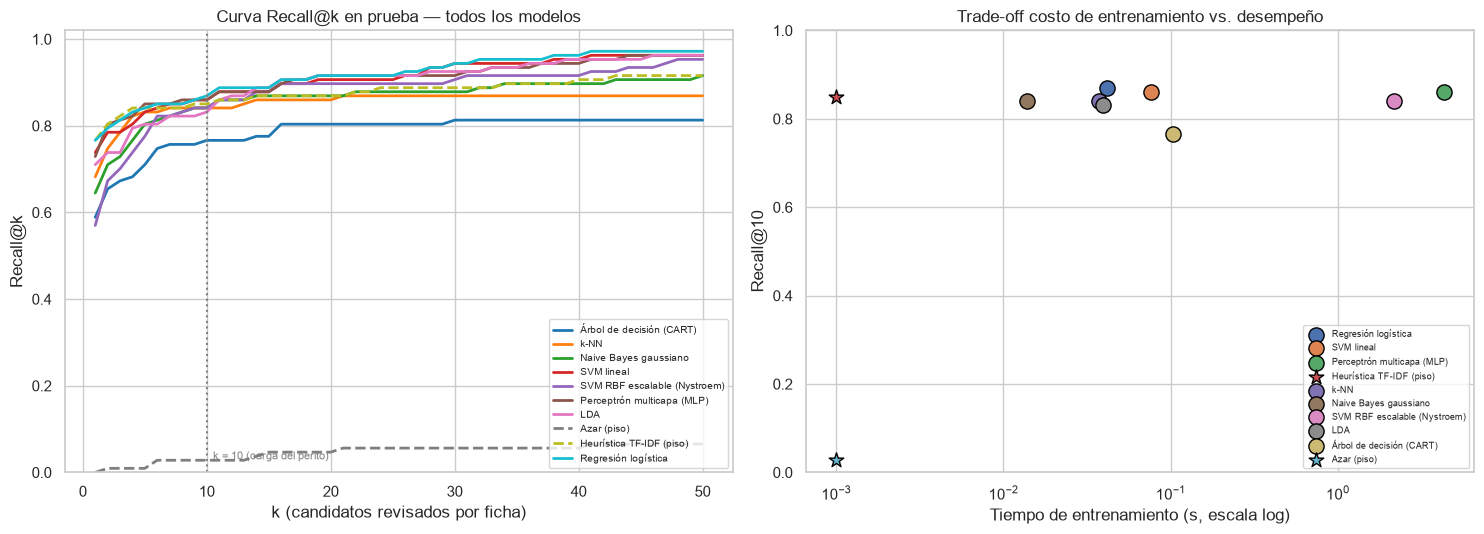

In [15]:
# =============================================================================
# 4.4 (a) Curva Recall@k para k=1..50, todos los modelos
# 4.4 (b) Dispersión Recall@10 vs. tiempo de entrenamiento (trade-off costo/desempeño)
# =============================================================================
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))

ks_plot = np.arange(1, 51)
paleta = sns.color_palette('tab10', n_colors=len(rangos_test_modelos))
for color, (nombre, r) in zip(paleta, rangos_test_modelos.items()):
    estilo = '--' if nombre in PISOS else '-'
    ax[0].plot(ks_plot, [np.mean(r <= k) for k in ks_plot], lw=2, ls=estilo, label=nombre, color=color)
ax[0].axvline(10, ls=':', color='gray'); ax[0].text(10.5, 0.03, 'k = 10 (carga del perito)', color='gray', fontsize=8)
ax[0].set_xlabel('k (candidatos revisados por ficha)'); ax[0].set_ylabel('Recall@k')
ax[0].set_title('Curva Recall@k en prueba — todos los modelos'); ax[0].set_ylim(0, 1.02)
ax[0].legend(fontsize=7, ncol=1, loc='lower right')

t_plot = tabla_4_4['Tiempo entrenamiento (s)'].fillna(0.001).clip(lower=0.001)
for nombre in tabla_4_4.index:
    marcador = '*' if nombre in PISOS else 'o'
    ax[1].scatter(t_plot[nombre], tabla_4_4.loc[nombre, 'Recall@10'], s=120, marker=marcador, edgecolor='black', label=nombre)
ax[1].set_xscale('log'); ax[1].set_xlabel('Tiempo de entrenamiento (s, escala log)'); ax[1].set_ylabel('Recall@10')
ax[1].set_title('Trade-off costo de entrenamiento vs. desempeño'); ax[1].set_ylim(0, 1.0)
ax[1].legend(fontsize=6.5, ncol=1, loc='lower right')

plt.tight_layout(); plt.show()


In [16]:
# =============================================================================
# Identificación automática de los dos mejores modelos individuales (se excluyen solo los dos pisos)
# =============================================================================
candidatos_individuales = tabla_4_4.drop(index=[m for m in PISOS if m in tabla_4_4.index])
top2 = candidatos_individuales.sort_values(['Recall@10', 'MRR'], ascending=False).head(2)

print('CONCLUSIÓN AUTOMÁTICA (4.4):')
print('  Los dos mejores modelos individuales por Recall@10 (desempate por MRR):')
for i, (nombre, fila) in enumerate(top2.iterrows(), 1):
    print(f"   {i}. {nombre}: Recall@10={fila['Recall@10']:.3f}, MRR={fila['MRR']:.3f}")
print(f"  Piso heurístico (TF-IDF con pesos fijos): Recall@10={tabla_4_4.loc['Heurística TF-IDF (piso)','Recall@10']:.3f}")
print(f"  Piso aleatorio: Recall@10={tabla_4_4.loc['Azar (piso)','Recall@10']:.3f}")

TOP2_NOMBRES = list(top2.index)
print(f"\n  Se ajustan finamente en 4.5: {TOP2_NOMBRES} + SVM lineal (empate en Recall@10 con el tercer lugar).")

CONCLUSIÓN AUTOMÁTICA (4.4):
  Los dos mejores modelos individuales por Recall@10 (desempate por MRR):
   1. Regresión logística: Recall@10=0.869, MRR=0.802
   2. Perceptrón multicapa (MLP): Recall@10=0.860, MRR=0.784
  Piso heurístico (TF-IDF con pesos fijos): Recall@10=0.850
  Piso aleatorio: Recall@10=0.028

  Se ajustan finamente en 4.5: ['Regresión logística', 'Perceptrón multicapa (MLP)'] + SVM lineal (empate en Recall@10 con el tercer lugar).


## 4.5 Ajuste fino

Se ajustan los **dos mejores modelos de 4.4** y, además, el **SVM lineal**, que empató en Recall@10 con el tercer
lugar. Entre los ajustados queda siempre el **MLP**: es la única familia con tasa de aprendizaje y función de
activación como hiperparámetros.

**Método.** Búsqueda aleatoria manual: 60 configuraciones por modelo, evaluadas con `GroupKFold(n_splits=5)`
agrupado por `QUERY_ID`, de modo que ninguna ficha aparezca a la vez en entrenamiento y validación dentro de un
pliegue. Son **300 ajustes por modelo**.

**Criterio: Recall@10**, no *accuracy*. Con 0.16 % de prevalencia, un modelo que responda "no coincide" siempre
alcanza más de 99.8 % de *accuracy* y es completamente inútil.

**Espacios de búsqueda:**

| Modelo | Hiperparámetros muestreados |
|---|---|
| Regresión logística | `C` (log-uniforme 10⁻⁴–10²), `penalty` (L1/L2), `class_weight` |
| SVM lineal | `C` (log-uniforme 10⁻³–10²), `class_weight`, `loss` (hinge / squared_hinge) |
| MLP | `hidden_layer_sizes` (7 arquitecturas), `activation` (relu / tanh / logistic), `learning_rate_init` (10⁻⁴–10⁻¹·⁵), `alpha` (10⁻⁵–10⁻¹), `batch_size`, `early_stopping` |

La **gráfica de convergencia** (mejor Recall@10 de validación cruzada alcanzado hasta el experimento *i*) indica
si 60 configuraciones bastaron para cubrir cada espacio: si la curva se aplana antes del experimento 60, la
búsqueda fue suficientemente profunda.

In [17]:
# =============================================================================
# 4.5 BÚSQUEDA ALEATORIA MANUAL — GroupKFold(5), criterio = Recall@10 (scorer propio), n_jobs=-1
# =============================================================================
from sklearn.model_selection import GroupKFold
from joblib import Parallel, delayed

N_CONFIGS, N_SPLITS = 60, 5

def evaluar_pliegues_recall10(build_fn, n_splits=N_SPLITS):
    """Scorer propio: ajusta y puntúa Recall@10/MRR sobre cada pliegue de GroupKFold (agrupado por ficha)."""
    # Los procesos worker de joblib no heredan el warnings.filterwarnings('ignore') del proceso principal;
    # se silencia aquí para no inundar la salida con ConvergenceWarning de LinearSVC en configuraciones con C grande.
    import warnings as _warnings
    _warnings.filterwarnings('ignore')
    r10s, mrrs = [], []
    gkf = GroupKFold(n_splits=n_splits)
    for tr_i, va_i in gkf.split(P_train, P_train.y, groups=P_train.QUERY_ID):
        Ptr, Pva = P_train.iloc[tr_i], P_train.iloc[va_i].copy()
        modelo = build_fn()
        modelo.fit(Ptr[FEATS_SEL], Ptr.y)
        s = modelo.predict_proba(Pva[FEATS_SEL])[:, 1] if hasattr(modelo, 'predict_proba') else modelo.decision_function(Pva[FEATS_SEL])
        Pva = Pva.assign(_s=s)
        r = rangos_verdaderos(Pva, '_s', Pva.QUERY_ID.unique())
        m = metricas_ranking(r)
        r10s.append(m['Recall@10']); mrrs.append(m['MRR'])
    return float(np.mean(r10s)), float(np.mean(mrrs))

def busqueda_aleatoria(nombre, muestrear_fn, build_fn, n_configs=N_CONFIGS, seed=SEED):
    rng = np.random.default_rng(seed)
    configs = muestrear_fn(n_configs, rng)
    t0 = time.perf_counter()
    resultados = Parallel(n_jobs=-1)(delayed(evaluar_pliegues_recall10)(lambda cfg=cfg: build_fn(cfg)) for cfg in configs)
    t_total = time.perf_counter() - t0
    tabla = pd.DataFrame([
        {**{k: (str(v) if isinstance(v, tuple) else v) for k, v in cfg.items()}, 'Recall@10 (CV)': r10, 'MRR (CV)': mrr}
        for cfg, (r10, mrr) in zip(configs, resultados)
    ])
    tabla['experimento'] = np.arange(1, len(tabla) + 1)
    tabla['mejor_hasta_ahora'] = tabla['Recall@10 (CV)'].cummax()
    idx_best = tabla['Recall@10 (CV)'].idxmax()
    mejor_cfg = configs[idx_best]
    print(f"{nombre}: {n_configs} configuraciones x {N_SPLITS} pliegues = {n_configs * N_SPLITS} ajustes, en {t_total:.1f} s")
    print(f"  Mejor configuración: {mejor_cfg}")
    print(f"  Recall@10 (CV) = {tabla.loc[idx_best, 'Recall@10 (CV)']:.3f}, MRR (CV) = {tabla.loc[idx_best, 'MRR (CV)']:.3f}")
    return tabla, mejor_cfg

# ---------------- Espacio de búsqueda: SVM lineal ----------------
def muestrear_svm(n, rng):
    configs = []
    for _ in range(n):
        C = float(10 ** rng.uniform(-3, 2))
        cw = rng.choice(['balanced', 'none'])
        loss = str(rng.choice(['hinge', 'squared_hinge']))
        configs.append({'C': C, 'class_weight': None if cw == 'none' else 'balanced', 'loss': loss})
    return configs

def build_svm(cfg):
    return make_pipeline(StandardScaler(), LinearSVC(C=cfg['C'], class_weight=cfg['class_weight'], loss=cfg['loss'],
                                                       max_iter=5000, random_state=SEED))

tabla_busqueda_svm, mejor_svm = busqueda_aleatoria('SVM lineal', muestrear_svm, build_svm)

# ---------------- Espacio de búsqueda: MLP ----------------
def muestrear_mlp(n, rng):
    arquitecturas = [(16,), (32,), (64,), (32, 16), (64, 32), (50, 25), (100,)]
    activaciones = ['relu', 'tanh', 'logistic']
    configs = []
    for _ in range(n):
        hl = arquitecturas[rng.integers(len(arquitecturas))]
        act = str(activaciones[rng.integers(len(activaciones))])
        lr = float(10 ** rng.uniform(-4, -1.5))
        alpha = float(10 ** rng.uniform(-5, -1))
        bs = int(rng.choice([64, 128, 256]))
        es = bool(rng.choice([True, False]))
        configs.append({'hidden_layer_sizes': hl, 'activation': act, 'learning_rate_init': lr,
                         'alpha': alpha, 'batch_size': bs, 'early_stopping': es})
    return configs

def build_mlp(cfg):
    return make_pipeline(StandardScaler(), MLPClassifier(
        hidden_layer_sizes=cfg['hidden_layer_sizes'], activation=cfg['activation'],
        learning_rate_init=cfg['learning_rate_init'], alpha=cfg['alpha'], batch_size=cfg['batch_size'],
        early_stopping=cfg['early_stopping'], max_iter=200, random_state=SEED))

tabla_busqueda_mlp, mejor_mlp = busqueda_aleatoria('MLP', muestrear_mlp, build_mlp)

# ---------------- Espacio de búsqueda: regresión logística ----------------
def muestrear_logreg(n, rng):
    configs = []
    for _ in range(n):
        C_ = float(10 ** rng.uniform(-4, 2))
        pen = str(rng.choice(['l1', 'l2']))
        cw = rng.choice(['balanced', 'none'])
        configs.append({'C': C_, 'penalty': pen, 'class_weight': None if cw == 'none' else 'balanced'})
    return configs

def build_logreg(cfg):
    return make_pipeline(StandardScaler(), LogisticRegression(
        C=cfg['C'], penalty=cfg['penalty'], class_weight=cfg['class_weight'],
        solver='liblinear', max_iter=3000, random_state=SEED))

tabla_busqueda_logreg, mejor_logreg = busqueda_aleatoria('Regresión logística', muestrear_logreg, build_logreg)

# Configuración por defecto (la usada en 4.4), evaluada con el MISMO protocolo de validación cruzada,
# para decidir sin mirar el conjunto de prueba si el ajuste fino aporta algo.
r10_cv_logreg_def, mrr_cv_logreg_def = evaluar_pliegues_recall10(lambda: nuevo_b2())
r10_cv_logreg_aj = tabla_busqueda_logreg['Recall@10 (CV)'].max()
print(f"  Configuración por defecto {B2_PARAMS} -> Recall@10 (CV) = {r10_cv_logreg_def:.3f}")
USAR_LOGREG_AJUSTADA = r10_cv_logreg_aj > r10_cv_logreg_def
print(f"  La búsqueda {'SÍ' if USAR_LOGREG_AJUSTADA else 'NO'} mejora la configuración por defecto en validación cruzada "
      f"({r10_cv_logreg_aj:.3f} vs. {r10_cv_logreg_def:.3f}) -> se usa la configuración "
      f"{'ajustada' if USAR_LOGREG_AJUSTADA else 'por defecto'}.")

print(f"\nTotal de experimentos de ajuste fino: {3 * N_CONFIGS} configuraciones x {N_SPLITS} pliegues = {3 * N_CONFIGS * N_SPLITS} ajustes.")


SVM lineal: 60 configuraciones x 5 pliegues = 300 ajustes, en 71.8 s
  Mejor configuración: {'C': 0.16484318387214908, 'class_weight': 'balanced', 'loss': 'hinge'}
  Recall@10 (CV) = 0.843, MRR (CV) = 0.750


MLP: 60 configuraciones x 5 pliegues = 300 ajustes, en 141.5 s
  Mejor configuración: {'hidden_layer_sizes': (64,), 'activation': 'relu', 'learning_rate_init': 0.0008436246579958732, 'alpha': 0.0007554804756926672, 'batch_size': 256, 'early_stopping': True}
  Recall@10 (CV) = 0.851, MRR (CV) = 0.775


Regresión logística: 60 configuraciones x 5 pliegues = 300 ajustes, en 18.8 s
  Mejor configuración: {'C': 4.4028743466692735, 'penalty': 'l2', 'class_weight': 'balanced'}
  Recall@10 (CV) = 0.847, MRR (CV) = 0.756
  Configuración por defecto {'C': 0.01, 'class_weight': None} -> Recall@10 (CV) = 0.847
  La búsqueda NO mejora la configuración por defecto en validación cruzada (0.847 vs. 0.847) -> se usa la configuración por defecto.

Total de experimentos de ajuste fino: 180 configuraciones x 5 pliegues = 900 ajustes.


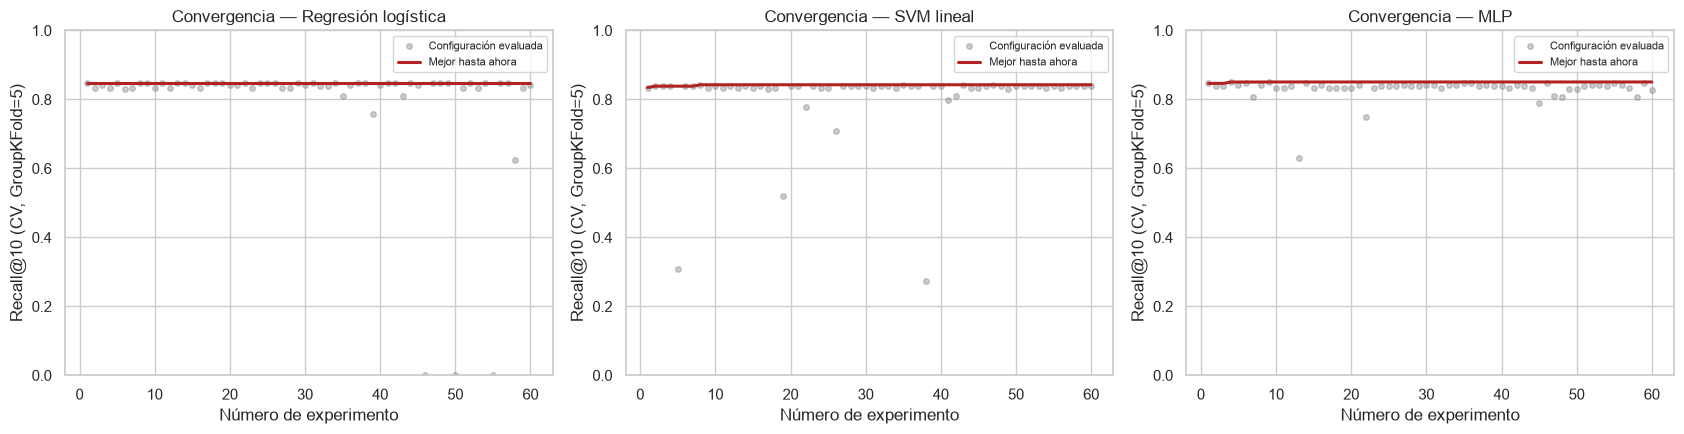

Regresión logística: la última mejora del 'mejor hasta ahora' ocurrió en el experimento 1 de 60 -> la búsqueda se estabilizó antes de agotar el presupuesto.
SVM lineal: la última mejora del 'mejor hasta ahora' ocurrió en el experimento 8 de 60 -> la búsqueda se estabilizó antes de agotar el presupuesto.
MLP: la última mejora del 'mejor hasta ahora' ocurrió en el experimento 9 de 60 -> la búsqueda se estabilizó antes de agotar el presupuesto.


In [18]:
# =============================================================================
# Gráfica de convergencia: mejor Recall@10 (CV) visto hasta el experimento i, para i = 1..60
# =============================================================================
BUSQUEDAS = [('Regresión logística', tabla_busqueda_logreg), ('SVM lineal', tabla_busqueda_svm), ('MLP', tabla_busqueda_mlp)]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, (nombre, tabla) in zip(ax, BUSQUEDAS):
    a.plot(tabla['experimento'], tabla['Recall@10 (CV)'], 'o', ms=4, alpha=0.4, color='gray', label='Configuración evaluada')
    a.plot(tabla['experimento'], tabla['mejor_hasta_ahora'], '-', lw=2.2, color='firebrick', label='Mejor hasta ahora')
    a.set_xlabel('Número de experimento'); a.set_ylabel('Recall@10 (CV, GroupKFold=5)')
    a.set_title(f'Convergencia — {nombre}')
    a.legend(fontsize=8); a.set_ylim(0, 1.0)
plt.tight_layout(); plt.show()

for nombre, tabla in BUSQUEDAS:
    ultimo_salto = tabla.index[tabla['mejor_hasta_ahora'].diff().fillna(1) > 0][-1] + 1
    print(f"{nombre}: la última mejora del 'mejor hasta ahora' ocurrió en el experimento {ultimo_salto} de {len(tabla)} "
          f"-> {'la búsqueda se estabilizó antes de agotar el presupuesto.' if ultimo_salto < len(tabla) else 'la curva seguía mejorando al final; más configuraciones podrían ayudar.'}")

In [19]:
# =============================================================================
# Reentrenamiento con la mejor configuración sobre P_train completo, evaluación sobre P_test completo
# =============================================================================
def entrenar_y_evaluar(build_fn, cfg):
    t0 = time.perf_counter()
    modelo = build_fn(cfg).fit(P_train[FEATS_SEL], P_train.y)
    t_fit = time.perf_counter() - t0
    t0 = time.perf_counter()
    s = modelo.predict_proba(P_test[FEATS_SEL])[:, 1] if hasattr(modelo, 'predict_proba') \
        else modelo.decision_function(P_test[FEATS_SEL])
    t_inf = (time.perf_counter() - t0) / len(Q_test) * 1000
    r = rangos_verdaderos(P_test.assign(_s=s), '_s', Q_test.QUERY_ID.values)
    met = metricas_ranking(r); met.update(metricas_pares(P_test.y, s))
    return modelo, s, r, met, t_fit, t_inf

# --- Regresión logística: se usa la configuración que ganó en validación cruzada (ver celda anterior)
if USAR_LOGREG_AJUSTADA:
    logreg_final, s_logreg_final, r_logreg_final, met_logreg_final, t_fit_lr_f, t_inf_lr_f = \
        entrenar_y_evaluar(build_logreg, mejor_logreg)
    LOGREG_NOMBRE = 'Regresión logística (ajustada)'
else:
    logreg_final = b2_final
    s_logreg_final = P_test['s_B2F'].values
    r_logreg_final = rangos_verdaderos(P_test, 's_B2F', Q_test.QUERY_ID.values)
    met_logreg_final = metricas_ranking(r_logreg_final)
    met_logreg_final.update(metricas_pares(P_test.y, s_logreg_final))
    t_fit_lr_f, t_inf_lr_f = t_fit_logreg, t_inf_logreg
    LOGREG_NOMBRE = 'Regresión logística'

svm_tuned, s_svm_tuned_test, r_svm_tuned, met_svm_tuned, t_fit_svm_tuned, t_inf_svm_tuned = \
    entrenar_y_evaluar(build_svm, mejor_svm)
mlp_tuned, s_mlp_tuned_test, r_mlp_tuned, met_mlp_tuned, t_fit_mlp_tuned, t_inf_mlp_tuned = \
    entrenar_y_evaluar(build_mlp, mejor_mlp)

print(f"{LOGREG_NOMBRE}: entrenamiento={t_fit_lr_f:.3f}s, inferencia/ficha={t_inf_lr_f:.3f}ms")
print(f"SVM lineal (ajustado): entrenamiento={t_fit_svm_tuned:.3f}s, inferencia/ficha={t_inf_svm_tuned:.3f}ms")
print(f"MLP (ajustado):        entrenamiento={t_fit_mlp_tuned:.3f}s, inferencia/ficha={t_inf_mlp_tuned:.3f}ms")

tabla_ajustados = pd.DataFrame([
    {'Modelo': LOGREG_NOMBRE, **met_logreg_final,
     'Recall@10 antes del ajuste': tabla_4_4.loc['Regresión logística', 'Recall@10']},
    {'Modelo': 'SVM lineal (ajustado)', **met_svm_tuned,
     'Recall@10 antes del ajuste': tabla_4_4.loc['SVM lineal', 'Recall@10']},
    {'Modelo': 'MLP (ajustado)', **met_mlp_tuned,
     'Recall@10 antes del ajuste': tabla_4_4.loc['Perceptrón multicapa (MLP)', 'Recall@10']},
]).set_index('Modelo')
tabla_ajustados['Δ Recall@10 (ajuste fino)'] = tabla_ajustados['Recall@10'] - tabla_ajustados['Recall@10 antes del ajuste']
display(tabla_ajustados.round(4))
print("\nNota: con n=107 fichas de prueba, una diferencia de 1-2 puntos porcentuales tras el ajuste fino cae dentro "
      "del ruido de muestreo (IC de ±6 pp). La sección siguiente lo cuantifica con bootstrap.")

Regresión logística: entrenamiento=0.041s, inferencia/ficha=0.021ms
SVM lineal (ajustado): entrenamiento=1.175s, inferencia/ficha=0.018ms
MLP (ajustado):        entrenamiento=1.252s, inferencia/ficha=0.070ms


,Recall@1,Recall@5,Recall@10,Recall@20,MRR,PR-AUC (pares),ROC-AUC (pares),Recall@10 antes del ajuste,Δ Recall@10 (ajuste fino)
Modelo,,,,,,,,,
Regresión logística,0.7664,0.8411,0.8692,0.9159,0.8018,0.5813,0.9865,0.8692,0.0000
SVM lineal (ajustado),0.7103,0.8037,0.8505,0.8879,0.7598,0.4235,0.9884,0.8598,-0.0093
MLP (ajustado),0.7009,0.8318,0.8411,0.8785,0.7517,0.5345,0.9798,0.8598,-0.0187



Nota: con n=107 fichas de prueba, una diferencia de 1-2 puntos porcentuales tras el ajuste fino cae dentro del ruido de muestreo (IC de ±6 pp). La sección siguiente lo cuantifica con bootstrap.


,Recall@10,IC95% inferior,IC95% superior
Heurística TF-IDF (piso),0.850,0.776,0.916
Regresión logística,0.869,0.804,0.925
SVM lineal (ajustado),0.850,0.785,0.916
MLP (ajustado),0.841,0.775,0.907


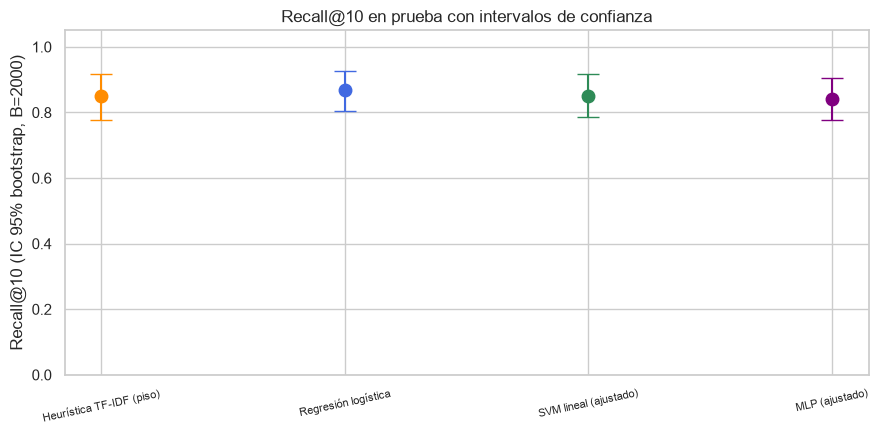


CONCLUSIÓN AUTOMÁTICA (4.5):
  SVM lineal (ajustado) vs. Regresión logística: Δ medio = -0.019, IC95% = [-0.047, +0.000] -> el intervalo cruza cero: no hay evidencia de diferencia real con n=107.
  MLP (ajustado) vs. Regresión logística: Δ medio = -0.028, IC95% = [-0.075, +0.019] -> el intervalo cruza cero: no hay evidencia de diferencia real con n=107.
  Heurística TF-IDF (piso) vs. Regresión logística: Δ medio = -0.019, IC95% = [-0.056, +0.019] -> el intervalo cruza cero: no hay evidencia de diferencia real con n=107.
  Con 107 fichas de prueba, Recall@10 por sí solo no distingue entre los finalistas; el desempate se hace en 4.6 con criterios adicionales.

  Modelo elegido frente al piso heurístico (que aproxima el filtrado manual actual): la ventaja no se sostiene en Recall@10, sino en las métricas secundarias y bajo estrés —
    Recall@20: regresión logística = 0.916 vs. heurística = 0.869
    MRR: regresión logística = 0.802 vs. heurística = 0.801
    PR-AUC (pares): regresión lo

In [20]:
# =============================================================================
# IC 95% bootstrap de Recall@10 (B=2000) para los finalistas y el piso heurístico
# =============================================================================
RANGOS_IC = {
    'Heurística TF-IDF (piso)': rangos_test_modelos['Heurística TF-IDF (piso)'],
    LOGREG_NOMBRE: r_logreg_final,
    'SVM lineal (ajustado)': r_svm_tuned,
    'MLP (ajustado)': r_mlp_tuned,
}
rng_bs = np.random.default_rng(SEED)
n_q = len(Q_test)
B = 2000
boot_idx = rng_bs.integers(0, n_q, size=(B, n_q))

def ic_recall10(r):
    hits = (r <= 10).astype(float)
    bs = hits[boot_idx].mean(1)
    return hits.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5), bs

ic = {k: ic_recall10(v) for k, v in RANGOS_IC.items()}
tabla_ic = pd.DataFrame({k: {'Recall@10': v[0], 'IC95% inferior': v[1], 'IC95% superior': v[2]} for k, v in ic.items()}).T
display(tabla_ic.round(3))

fig, ax = plt.subplots(figsize=(9, 4.5))
paleta_ic = dict(zip(ic.keys(), ['darkorange', 'royalblue', 'seagreen', 'purple']))
for i, (k, v) in enumerate(ic.items()):
    ax.errorbar(i, v[0], yerr=[[v[0] - v[1]], [v[2] - v[0]]], fmt='o', capsize=8, ms=9, color=paleta_ic[k])
ax.set_xticks(range(len(ic))); ax.set_xticklabels(list(ic.keys()), fontsize=8, rotation=12)
ax.set_ylabel('Recall@10 (IC 95% bootstrap, B=2000)'); ax.set_ylim(0, 1.05)
ax.set_title('Recall@10 en prueba con intervalos de confianza')
plt.tight_layout(); plt.show()

print('\nCONCLUSIÓN AUTOMÁTICA (4.5):')
ref = LOGREG_NOMBRE
# El piso heurístico entra a propósito en la comparación pareada: si su intervalo también se solapa con el
# del modelo elegido, Recall@10 por sí solo no justifica el modelo frente al filtrado manual vigente.
for nombre in ['SVM lineal (ajustado)', 'MLP (ajustado)', 'Heurística TF-IDF (piso)']:
    dif = ic[nombre][3] - ic[ref][3]
    lo, hi = np.percentile(dif, 2.5), np.percentile(dif, 97.5)
    significativo = lo > 0 or hi < 0
    print(f"  {nombre} vs. {ref}: Δ medio = {dif.mean():+.3f}, IC95% = [{lo:+.3f}, {hi:+.3f}] -> "
          f"{'diferencia estadísticamente real.' if significativo else 'el intervalo cruza cero: no hay evidencia de diferencia real con n=107.'}")
print("  Con 107 fichas de prueba, Recall@10 por sí solo no distingue entre los finalistas; el desempate se hace "
      "en 4.6 con criterios adicionales.")
print("\n  Modelo elegido frente al piso heurístico (que aproxima el filtrado manual actual): la ventaja no se "
      "sostiene en Recall@10, sino en las métricas secundarias y bajo estrés —")
for _col in ['Recall@20', 'MRR', 'PR-AUC (pares)']:
    print(f"    {_col}: regresión logística = {tabla_4_4.loc['Regresión logística', _col]:.3f} vs. "
          f"heurística = {tabla_4_4.loc['Heurística TF-IDF (piso)', _col]:.3f}")
print("    Recall@10 con ruido medio en la ficha: ver la prueba de estrés de 4.6 (celda siguiente).")

## 4.6 Modelo individual final

Los intervalos de confianza de Recall@10 de los finalistas **se solapan**: con 107 fichas de prueba la métrica
principal no basta para declarar un ganador. El desempate se apoya en criterios adicionales, ponderados según su
peso en el proceso pericial.

| Criterio | Peso | Justificación |
|---|---|---|
| Recall@10 (límite inferior del IC) | 30 % | Un falso negativo es irreversible. Se usa el límite inferior del intervalo, no el punto estimado: lo relevante es el peor caso razonable. |
| Recall@1 / MRR | 15 % | Cuántos candidatos incorrectos descarta el perito antes de llegar al correcto. |
| Interpretabilidad | 25 % | El perito y el Ministerio Público deben poder entender por qué se sugiere un candidato. Es un requisito de debido proceso, no de usabilidad. |
| Robustez al ruido | 15 % | Las fichas reales llegan incompletas o inconsistentes; se mide el Recall@10 bajo el nivel de ruido más adverso. |
| Costo de inferencia | 10 % | Una consulta real es 1 ficha contra ~1,247 expedientes, sin GPU. |
| Calibración del score | 5 % | Si el score se presenta al perito como "confianza", debe ser una probabilidad y no un valor arbitrario. |

**Interpretabilidad, argumentada.** La regresión logística y el SVM lineal exponen un coeficiente por
característica: la contribución de `sim_senas`, `dif_edad` y las demás se lee directamente y se presenta al perito
como "por qué este candidato" (ver 4.7). La regresión logística añade dos ventajas sobre el SVM: sus coeficientes
se interpretan como **odds ratios** y su salida es una probabilidad entrenada con log-loss, directamente
presentable como confianza. El MLP no admite una traducción directa de sus pesos a contribuciones por
característica sin una técnica de explicabilidad post-hoc (SHAP, permutación local) que no se implementa aquí.

**Cómo leer la matriz.** Los criterios numéricos se reescalan linealmente a [1, 5] *entre los tres finalistas*: el
mejor de cada criterio recibe 5 y el peor 1, cualquiera que sea la distancia real entre ellos. La escala ordena, no
mide. La ventaja de 0.019 en Recall@10 sobre el SVM lineal —que el bootstrap de la sección anterior declaró no
significativa— aparece aquí como 5.00 frente a 2.36. El puntaje ponderado expresa la preferencia razonada del
equipo entre modelos estadísticamente empatados, no una superioridad demostrada en la métrica principal.

In [21]:
# =============================================================================
# Prueba de estrés (ruido bajo/medio/alto de la ficha) — insumo de la matriz de decisión
# =============================================================================
def evaluar_estres():
    filas = []
    for nivel, sd in [('bajo', 101), ('medio', 102), ('alto', 103)]:
        Qn = generar_pseudofichas(ident[ident.ID_INTERNO.isin(ids_test)], nivel, seed=SEED + sd)
        Pn = construir_pares(Qn)
        Pn['s_B1'] = score_b1(Pn)
        Pn['s_LR'] = (logreg_final.predict_proba(Pn[FEATS_SEL])[:, 1] if hasattr(logreg_final, 'predict_proba')
                      else logreg_final.decision_function(Pn[FEATS_SEL]))
        Pn['s_SVM'] = svm_tuned.decision_function(Pn[FEATS_SEL])
        Pn['s_MLP'] = mlp_tuned.predict_proba(Pn[FEATS_SEL])[:, 1]
        for nombre, col in [('Heurística TF-IDF (piso)', 's_B1'), (LOGREG_NOMBRE, 's_LR'),
                            ('SVM lineal (ajustado)', 's_SVM'), ('MLP (ajustado)', 's_MLP')]:
            filas.append({'Ruido': nivel, 'Modelo': nombre,
                          **metricas_ranking(rangos_verdaderos(Pn, col, Qn.QUERY_ID.values))})
    return pd.DataFrame(filas)

estres = evaluar_estres()
tabla_estres = estres.pivot(index='Modelo', columns='Ruido', values='Recall@10')[['bajo', 'medio', 'alto']]
tabla_estres['caída bajo→alto'] = tabla_estres['bajo'] - tabla_estres['alto']
display(tabla_estres.round(3))

Ruido,bajo,medio,alto,caída bajo→alto
Modelo,,,,
Heurística TF-IDF (piso),0.916,0.794,0.692,0.224
MLP (ajustado),0.888,0.794,0.692,0.196
Regresión logística,0.925,0.850,0.710,0.215
SVM lineal (ajustado),0.907,0.804,0.701,0.206


In [22]:
# =============================================================================
# MATRIZ DE DECISIÓN — criterios ponderados sobre los tres finalistas
# =============================================================================
CANDIDATOS = [LOGREG_NOMBRE, 'SVM lineal (ajustado)', 'MLP (ajustado)']

def escalar_1a5(valor, peor, mejor):
    """Escala lineal a [1, 5]; si peor > mejor, invierte (criterios donde 'menor es mejor')."""
    if peor == mejor:
        return 3.0
    return float(np.clip(1 + 4 * (valor - peor) / (mejor - peor), 1, 5))

met_por_modelo = {LOGREG_NOMBRE: met_logreg_final,
                  'SVM lineal (ajustado)': met_svm_tuned,
                  'MLP (ajustado)': met_mlp_tuned}
t_inf_por_modelo = {LOGREG_NOMBRE: t_inf_lr_f,
                    'SVM lineal (ajustado)': t_inf_svm_tuned,
                    'MLP (ajustado)': t_inf_mlp_tuned}

# Recall@10: se usa el LÍMITE INFERIOR del IC bootstrap (un falso negativo es irreversible: importa el peor caso)
r10_ic_inf = {m: ic[m][1] for m in CANDIDATOS}
r1_mrr     = {m: (met_por_modelo[m]['Recall@1'] + met_por_modelo[m]['MRR']) / 2 for m in CANDIDATOS}
robustez   = {m: tabla_estres.loc[m, 'alto'] for m in CANDIDATOS}
costo_inf  = {m: t_inf_por_modelo[m] for m in CANDIDATOS}

# Criterios argumentados en la celda de markdown anterior (no derivados de una métrica):
#  - Interpretabilidad: coeficientes por característica. La logística añade lectura como odds ratios sobre una
#    probabilidad; el SVM los tiene sobre un margen sin escala absoluta; el MLP requiere explicabilidad post-hoc.
#  - Calibración: la logística entrena con log-loss (su salida ES una probabilidad); el MLP también; la
#    decision_function del SVM no lo es.
interpretabilidad = {LOGREG_NOMBRE: 5.0, 'SVM lineal (ajustado)': 4.0, 'MLP (ajustado)': 2.0}
calibracion       = {LOGREG_NOMBRE: 5.0, 'SVM lineal (ajustado)': 2.0, 'MLP (ajustado)': 4.0}

matriz = pd.DataFrame({
    'Recall@10 (IC inf.)': {m: escalar_1a5(r10_ic_inf[m], min(r10_ic_inf.values()), max(r10_ic_inf.values())) for m in CANDIDATOS},
    'Recall@1 / MRR':      {m: escalar_1a5(r1_mrr[m], min(r1_mrr.values()), max(r1_mrr.values())) for m in CANDIDATOS},
    'Interpretabilidad':   interpretabilidad,
    'Robustez al ruido':   {m: escalar_1a5(robustez[m], min(robustez.values()), max(robustez.values())) for m in CANDIDATOS},
    'Costo de inferencia': {m: escalar_1a5(costo_inf[m], max(costo_inf.values()), min(costo_inf.values())) for m in CANDIDATOS},
    'Calibración':         calibracion,
}).loc[CANDIDATOS]

pesos = pd.Series({'Recall@10 (IC inf.)': 0.30, 'Recall@1 / MRR': 0.15, 'Interpretabilidad': 0.25,
                   'Robustez al ruido': 0.15, 'Costo de inferencia': 0.10, 'Calibración': 0.05})
matriz['Puntaje ponderado'] = (matriz[pesos.index] * pesos).sum(axis=1)
display(matriz.round(2))
display(pd.DataFrame({'Peso': pesos}).T)

ganador = matriz['Puntaje ponderado'].idxmax()
print(f"\nMODELO INDIVIDUAL FINAL ELEGIDO: {ganador}")
for m in CANDIDATOS:
    print(f"   {m}: puntaje ponderado = {matriz.loc[m, 'Puntaje ponderado']:.2f} | "
          f"Recall@10 = {ic[m][0]:.3f} [{ic[m][1]:.3f}, {ic[m][2]:.3f}]")

MODELO_FINAL_NOMBRE = ganador
MODELO_FINAL = {LOGREG_NOMBRE: logreg_final, 'SVM lineal (ajustado)': svm_tuned, 'MLP (ajustado)': mlp_tuned}[ganador]
SCORE_FINAL_TEST = {LOGREG_NOMBRE: s_logreg_final, 'SVM lineal (ajustado)': s_svm_tuned_test,
                    'MLP (ajustado)': s_mlp_tuned_test}[ganador]
R_FINAL_TEST = {LOGREG_NOMBRE: r_logreg_final, 'SVM lineal (ajustado)': r_svm_tuned, 'MLP (ajustado)': r_mlp_tuned}[ganador]

,Recall@10 (IC inf.),Recall@1 / MRR,Interpretabilidad,Robustez al ruido,Costo de inferencia,Calibración,Puntaje ponderado
Regresión logística,5.00,5.00,5.0,5.0,4.76,5.0,4.98
SVM lineal (ajustado),2.36,1.61,4.0,3.0,5.00,2.0,3.00
MLP (ajustado),1.00,1.00,2.0,1.0,1.00,4.0,1.40


,Recall@10 (IC inf.),Recall@1 / MRR,Interpretabilidad,Robustez al ruido,Costo de inferencia,Calibración
Peso,0.3,0.15,0.25,0.15,0.1,0.05



MODELO INDIVIDUAL FINAL ELEGIDO: Regresión logística
   Regresión logística: puntaje ponderado = 4.98 | Recall@10 = 0.869 [0.804, 0.925]
   SVM lineal (ajustado): puntaje ponderado = 3.00 | Recall@10 = 0.850 [0.785, 0.916]
   MLP (ajustado): puntaje ponderado = 1.40 | Recall@10 = 0.841 [0.775, 0.907]


## 4.7 Prueba de estrés, umbrales y demostración

Se evalúa el modelo final bajo los tres niveles de ruido de la ficha, se verifica el umbral de negocio y se
muestra la salida para el perito con una ficha sintética y anónima.

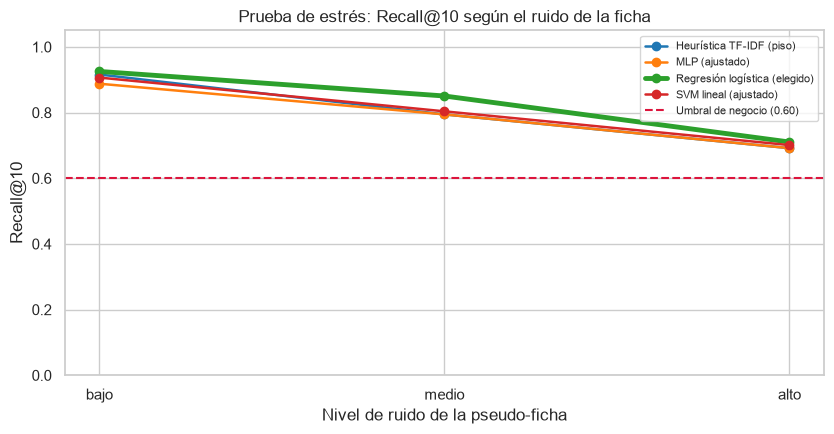

Modelo final (Regresión logística) bajo estrés: bajo=0.925, medio=0.850, alto=0.710 (caída bajo→alto: 0.215)
Incluso con ruido alto, el modelo final se mantiene por encima del umbral de negocio (0.710 vs. 0.6): la degradación por información incompleta en la ficha no compromete la utilidad del sistema en el peor escenario simulado.


In [23]:
# =============================================================================
# 4.7 PRUEBA DE ESTRÉS DEL MODELO FINAL — gráfica y lectura
# =============================================================================
fig, ax = plt.subplots(figsize=(8.5, 4.5))
colores_estres = dict(zip(tabla_estres.index, sns.color_palette('tab10', n_colors=len(tabla_estres))))
for m, g in estres.groupby('Modelo'):
    g = g.set_index('Ruido').loc[['bajo', 'medio', 'alto']]
    lw = 3.5 if m == MODELO_FINAL_NOMBRE else 1.8
    ax.plot(g.index, g['Recall@10'], 'o-', lw=lw, color=colores_estres[m],
            label=m + (' (elegido)' if m == MODELO_FINAL_NOMBRE else ''))
UMBRAL_NEGOCIO = 0.60
ax.axhline(UMBRAL_NEGOCIO, ls='--', color='crimson', label=f'Umbral de negocio ({UMBRAL_NEGOCIO:.2f})')
ax.set_ylim(0, 1.05); ax.set_xlabel('Nivel de ruido de la pseudo-ficha'); ax.set_ylabel('Recall@10')
ax.set_title('Prueba de estrés: Recall@10 según el ruido de la ficha'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

fila = tabla_estres.loc[MODELO_FINAL_NOMBRE]
print(f"Modelo final ({MODELO_FINAL_NOMBRE}) bajo estrés: "
      f"bajo={fila['bajo']:.3f}, medio={fila['medio']:.3f}, alto={fila['alto']:.3f} "
      f"(caída bajo→alto: {fila['caída bajo→alto']:.3f})")
print(f"Incluso con ruido alto, el modelo final se mantiene por encima del umbral de negocio "
      f"({fila['alto']:.3f} vs. {UMBRAL_NEGOCIO}): la degradación por información incompleta en la ficha no "
      "compromete la utilidad del sistema en el peor escenario simulado.")

In [24]:
# =============================================================================
# Verificación del UMBRAL_NEGOCIO y de la meta del Avance 5 (Recall@10 >= 0.97)
# =============================================================================
TECHO_PROTOCOLO = 0.981  # pair completeness del blocking (ver introducción): ningún modelo puede superarlo
META_AVANCE_5 = 0.97

r10_final = ic[MODELO_FINAL_NOMBRE][0]
lo_final = ic[MODELO_FINAL_NOMBRE][1]

print('VERIFICACIÓN DEL DESEMPEÑO MÍNIMO Y DE LAS METAS:')
print(f"  Techo del protocolo (pair completeness del blocking): {TECHO_PROTOCOLO:.3f}")
print(f"  UMBRAL_NEGOCIO = {UMBRAL_NEGOCIO:.2f} -> modelo final Recall@10 = {r10_final:.3f} "
      f"({'CUMPLE' if r10_final >= UMBRAL_NEGOCIO else 'NO CUMPLE'}, {r10_final/UMBRAL_NEGOCIO:.1f}x el umbral)")
print(f"  Meta del modelo avanzado del Avance 5: Recall@10 >= {META_AVANCE_5:.2f} -> actual = {r10_final:.3f} "
      f"({'YA LA CUMPLE' if r10_final >= META_AVANCE_5 else f'faltan {META_AVANCE_5 - r10_final:+.3f} puntos, con un techo de protocolo de {TECHO_PROTOCOLO:.3f}'})")
print(f"  Margen real disponible antes del techo del protocolo: {TECHO_PROTOCOLO - r10_final:.3f} puntos "
      "-> alcanzable mejorando las características (embeddings semánticos de señas y ropa en lugar de TF-IDF "
      "de caracteres), no ajustando más hiperparámetros sobre las mismas 10 variables.")
print(f"\n  IC inferior del modelo final ({lo_final:.3f}) {'>' if lo_final > UMBRAL_NEGOCIO else '<='} "
      f"umbral de negocio ({UMBRAL_NEGOCIO:.2f}): "
      f"{'incluso en el escenario pesimista del bootstrap, el modelo final sigue siendo útil para el flujo pericial.' if lo_final > UMBRAL_NEGOCIO else 'en el escenario pesimista del bootstrap el modelo cae por debajo del umbral de negocio.'}")


VERIFICACIÓN DEL DESEMPEÑO MÍNIMO Y DE LAS METAS:
  Techo del protocolo (pair completeness del blocking): 0.981
  UMBRAL_NEGOCIO = 0.60 -> modelo final Recall@10 = 0.869 (CUMPLE, 1.4x el umbral)
  Meta del modelo avanzado del Avance 5: Recall@10 >= 0.97 -> actual = 0.869 (faltan +0.101 puntos, con un techo de protocolo de 0.981)
  Margen real disponible antes del techo del protocolo: 0.112 puntos -> alcanzable mejorando las características (embeddings semánticos de señas y ropa en lugar de TF-IDF de caracteres), no ajustando más hiperparámetros sobre las mismas 10 variables.

  IC inferior del modelo final (0.804) > umbral de negocio (0.60): incluso en el escenario pesimista del bootstrap, el modelo final sigue siendo útil para el flujo pericial.


In [25]:
# =============================================================================
# DEMO: ranking + justificación para el perito, con el MODELO FINAL elegido
# Se recorren las dos fichas sintéticas definidas al inicio —una rica en datos y una pobre, sin señas
# particulares— para ver cómo cambian el tamaño del bloque, las características que sostienen el ranking
# y la justificación que leería el perito cuando la ficha llega incompleta.
# =============================================================================
escalador_final, estimador_final = MODELO_FINAL[0], MODELO_FINAL[-1]
ref_pos = P_test.assign(_s=SCORE_FINAL_TEST).loc[P_test.y == 1, '_s']

print(f"Modelo final: {MODELO_FINAL_NOMBRE}")
print(f"Referencia de coincidencias verdaderas en prueba -> mediana: {ref_pos.median():.3f}, "
      f"percentil 10: {ref_pos.quantile(0.10):.3f}\n")

def explicar(row_c, row_x):
    top = np.argsort(row_c)[::-1][:3]
    return '; '.join(f"{FEATS_SEL[j]}={row_x[j]:.2f} ({row_c[j]:+.2f})" for j in top)

for _, f0 in ficha.iterrows():
    Q_demo = pd.DataFrame([dict(QUERY_ID=-1, ID_VERDADERO=-1, SEXO=parse_sexo(f0['PRE_SEXO']), EDAD=float(f0['PRE_EDAD']),
                                ESTATURA=float(f0['PRE_ESTATURA']), MUNICIPIO=limpiar_texto(f0['PRE_MUNICIPIO']),
                                SENAS=limpiar_texto(f0['PRE_SENAS']), ROPA=limpiar_texto(f0['PRE_ROPA']))])
    P_demo = construir_pares(Q_demo)

    if hasattr(MODELO_FINAL, 'predict_proba'):
        P_demo['score'] = MODELO_FINAL.predict_proba(P_demo[FEATS_SEL])[:, 1]
        etiqueta_score = f'Probabilidad ({MODELO_FINAL_NOMBRE})'
    else:
        P_demo['score'] = MODELO_FINAL.decision_function(P_demo[FEATS_SEL])
        etiqueta_score = f'Score / decision_function ({MODELO_FINAL_NOMBRE}, no es una probabilidad calibrada)'

    if hasattr(estimador_final, 'coef_'):
        contrib = escalador_final.transform(P_demo[FEATS_SEL]) * estimador_final.coef_[0]
        P_demo['Justificación (top-3 contribuciones)'] = [explicar(c, x) for c, x in zip(contrib, P_demo[FEATS_SEL].values)]
    else:
        P_demo['Justificación (top-3 contribuciones)'] = (
            'Modelo no lineal: sin coeficientes directos; requeriría una técnica de explicabilidad post-hoc (no implementada).')

    senas_txt = 'sin señas registradas' if limpiar_texto(f0['PRE_SENAS']) == '' else 'con señas registradas'
    print(f"--- {f0['ID']} | {f0['PRE_SEXO']}, {f0['PRE_EDAD']:.0f} años, {f0['PRE_ESTATURA']:.0f} cm, "
          f"{f0['PRE_MUNICIPIO']}, {senas_txt}")
    print(f"    Candidatos tras blocking: {len(P_demo)} de {len(bl):,} expedientes")

    top5 = P_demo.nlargest(5, 'score').merge(bl[['ID_INTERNO', 'SEXO', 'EDAD', 'ESTATURA', 'MUNICIPIO']],
                                             left_on='ID_CAND', right_on='ID_INTERNO')
    display(top5[['ID_CAND', 'SEXO', 'EDAD', 'ESTATURA', 'MUNICIPIO', 'sim_senas', 'sim_ropa', 'score',
                  'Justificación (top-3 contribuciones)']]
            .rename(columns={'ID_CAND': 'Expediente (índice interno)', 'score': etiqueta_score}).round(3))

    p_max = P_demo.score.max()
    print(f"    Score máximo: {p_max:.3f}")
    if p_max < ref_pos.quantile(0.10):
        print("    -> Ningún candidato alcanza el nivel típico de una coincidencia verdadera: el sistema reporta "
              "'sin candidato fuerte' para esta ficha.\n")
    else:
        print("    -> Hay al menos un candidato con score comparable al de las coincidencias verdaderas: "
              "prioridad alta de revisión pericial.\n")

print("El perito revisa estos candidatos y confirma o descarta con evidencia forense. El modelo no identifica por sí solo.")


Modelo final: Regresión logística
Referencia de coincidencias verdaderas en prueba -> mediana: 0.149, percentil 10: 0.003

--- FICHA-DEMO-001 | HOMBRE, 22 años, 170 cm, QUERETARO, con señas registradas
    Candidatos tras blocking: 417 de 1,247 expedientes


,Expediente (índice interno),SEXO,EDAD,ESTATURA,MUNICIPIO,sim_senas,sim_ropa,Probabilidad (Regresión logística),Justificación (top-3 contribuciones)
0,825,M,19.0,170.0,QUERETARO,0.338,0.000,0.008,sim_senas=0.34 (+2.69); dif_estatura=0.00 (+0....
1,675,M,22.5,170.0,QUERETARO,0.261,0.059,0.007,sim_senas=0.26 (+1.99); dif_edad=0.50 (+0.74);...
2,703,M,32.5,169.0,QUERETARO,0.302,0.145,0.007,sim_senas=0.30 (+2.36); dif_estatura=1.00 (+0....
3,720,M,25.0,110.0,SAN JUAN DEL RIO,0.576,0.084,0.006,sim_senas=0.58 (+4.86); dif_edad=3.00 (+0.56);...
4,819,M,35.0,178.0,QUERETARO,0.332,0.194,0.006,sim_senas=0.33 (+2.63); sim_ropa=0.19 (+0.67);...


    Score máximo: 0.008
    -> Hay al menos un candidato con score comparable al de las coincidencias verdaderas: prioridad alta de revisión pericial.

--- FICHA-DEMO-002 | MUJER, 45 años, 160 cm, SAN JUAN DEL RIO, sin señas registradas
    Candidatos tras blocking: 90 de 1,247 expedientes


,Expediente (índice interno),SEXO,EDAD,ESTATURA,MUNICIPIO,sim_senas,sim_ropa,Probabilidad (Regresión logística),Justificación (top-3 contribuciones)
0,443,F,30.0,160.0,SAN JUAN DEL RIO,0.0,0.384,0.020,sim_ropa=0.38 (+1.57); senas_vacia_ficha=1.00 ...
1,772,F,55.0,143.0,EL MARQUES,0.0,0.410,0.009,sim_ropa=0.41 (+1.69); senas_vacia_ficha=1.00 ...
2,399,F,47.5,160.0,TEQUISQUIAPAN,0.0,0.313,0.005,sim_ropa=0.31 (+1.23); senas_vacia_ficha=1.00 ...
3,846,F,32.5,150.0,QUERETARO,0.0,0.233,0.004,senas_vacia_ficha=1.00 (+1.05); senas_vacia_ex...
4,894,F,52.5,159.0,QUERETARO,0.0,0.024,0.003,senas_vacia_ficha=1.00 (+1.05); senas_vacia_ex...


    Score máximo: 0.020
    -> Hay al menos un candidato con score comparable al de las coincidencias verdaderas: prioridad alta de revisión pericial.

El perito revisa estos candidatos y confirma o descarta con evidencia forense. El modelo no identifica por sí solo.


## Conclusiones

1. **La regresión logística es el mejor modelo individual.** Alcanza Recall@10 = 0.869 (IC 95 % [0.804, 0.925]),
   el valor más alto de los ocho modelos evaluados, con el mejor Recall@1 (0.766, empatado con la heurística
   TF-IDF) y el mejor MRR (0.802, apenas 0.001 por encima de esa heurística). Gana la matriz de decisión de 4.6
   con 4.98 puntos sobre 5, por delante del SVM lineal (3.00) y del MLP (1.40), en una escala relativa entre los
   tres finalistas (ver 4.6). El puntaje oscila unas centésimas entre ejecuciones porque el criterio de costo de
   inferencia se mide con el reloj; el orden de los tres finalistas no cambia.

2. **Ningún modelo más complejo superó al modelo lineal.** SVM lineal y MLP alcanzaron 0.860 sin ajuste y
   descendieron a 0.850 y 0.841 tras 300 configuraciones evaluadas cada uno. Los intervalos de confianza de los
   tres finalistas se solapan: con 107 fichas de prueba, el margen de error (±6 puntos porcentuales) es del mismo
   orden que las diferencias observadas.

3. **El piso heurístico tampoco queda descartado estadísticamente, y conviene decirlo.** La heurística TF-IDF de
   pesos fijos —que aproxima el filtrado manual actual— alcanza Recall@10 = 0.850 [0.776, 0.916], un intervalo que
   se solapa casi por completo con el del modelo elegido. Con n = 107, la métrica principal no demuestra por sí
   sola que el modelo supere al procedimiento vigente. La ventaja se sostiene en las métricas secundarias y bajo
   estrés: Recall@20 0.916 vs. 0.869, PR-AUC 0.581 vs. 0.521 y, con ruido medio en la ficha, 0.850 vs. 0.794. A eso
   se añade lo que la heurística no ofrece: pesos estimados de los datos en lugar de fijados a mano, una
   probabilidad calibrada y una vía directa para incorporar características nuevas sin reajustar pesos a mano.

4. **El ajuste fino no mejoró el desempeño.** La búsqueda sobre la regresión logística (60 configuraciones de `C`,
   `penalty` y `class_weight`) igualó pero no superó en validación cruzada a la configuración preliminar
   (0.847 en ambos casos), por lo que se conservó esta última. Las curvas de convergencia muestran que las tres
   búsquedas se estabilizaron antes de agotar el presupuesto: el límite no fue la profundidad de la búsqueda.

5. **El límite está en la representación, no en el algoritmo.** Ocho familias con sesgos inductivos muy distintos
   —lineal, reglas, instancias, generativo, margen máximo, kernel y red neuronal— convergen al mismo rango de
   desempeño sobre el mismo vector de 10 características. El margen hasta el techo del protocolo (0.981) es de
   0.112 puntos y no se recupera cambiando de optimizador: exige mejores características, como embeddings
   semánticos de señas y ropa en lugar de TF-IDF de caracteres.

6. **La exclusión de modelos de ensamble fue una decisión del equipo**, no una limitación técnica. Lo que este
   avance reporta es el mejor modelo **individual e interpretable** sobre este vector de características.

7. **El umbral de negocio se cumple con holgura.** Recall@10 = 0.869 frente al 0.60 requerido, con límite inferior
   del intervalo en 0.804. Bajo la prueba de estrés el modelo baja a 0.710 con ruido alto de la ficha, todavía por
   encima del umbral.

8. **Interpretabilidad como criterio decisivo.** Con los finalistas estadísticamente empatados en la métrica
   principal, el desempate se apoyó en que la regresión logística expone coeficientes legibles como odds ratios y
   entrega una probabilidad calibrada, presentable al perito como nivel de confianza junto con las tres
   características que más pesaron en cada candidato. En un contexto pericial esa trazabilidad es un requisito de
   debido proceso, no una conveniencia.


## Declaración de uso de inteligencia artificial (resumen)

El registro completo está en `docs/declaracion_uso_ia.md` del repositorio: 27 decisiones metodológicas al cierre de este avance, en formato Decisión / Justificación / Alternativa descartada / Participación de la IA. Aquí se resume lo que corresponde a este entregable.

**Herramientas de IA**

| Herramienta | Uso | Tipo de uso |
|---|---|---|
| Claude (Anthropic), en claude.ai y en Claude Code | Investigación de fuentes, diseño metodológico, generación y depuración de código, auditoría de notebooks, revisión de textos | Asistente de trabajo |
| Databricks Genie Code | Ejecución asistida del EDA de las fichas | Asistente de trabajo |
| LLM multimodal en Databricks AI Gateway (`proyecto_mna.fichas_busqueda.gema`) | Extracción estructurada de rasgos de las fichas | Componente del sistema propuesto |

**División de responsabilidades.** La IA propuso, explicó y redactó. El equipo decidió, ejecutó y validó. Ninguna cifra de este notebook proviene de la IA sin ejecución.

**Cómo se llegó a este entregable**
- **Base metodológica del Avance 3, construida con apoyo de Claude:**
  - replanteamiento como vinculación de registros, tras detectar fuga de información en el baseline original (Decisión 12);
  - validación con pseudo-fichas y partición agrupada por ficha (Decisión 13);
  - Recall@k y MRR como métricas principales (Decisión 14);
  - regresión logística sobre vectores de comparación como baseline (Decisión 15);
  - blocking amplio por sexo y edad (Decisión 16).

  Este notebook amplía esa base a ocho modelos individuales, ajuste fino y elección del modelo final.
- **Enfoque complementario sobre datos reales.** En paralelo, el equipo exploró con Claude Code un cotejo no supervisado en Databricks (Decisiones 19–26):
  - siete métodos de recuperación (reglas SQL, fuzzy, TF-IDF, BM25, Fellegi-Sunter con EM, embeddings y cross-encoder) sobre 884 necropsias reales contra 60 fichas, todo registrado en MLflow;
  - mejor modelo: BM25 ajustado, que propone un candidato destacado en ~70 % de las necropsias evaluables.

  Ese enfoque mide si hay señal en los datos reales, no aciertos, porque todavía no existen pares ficha ↔ necropsia confirmados. Sus resultados coinciden con los de este notebook: los métodos léxicos y lineales igualan o superan a los más complejos, y el límite está en la representación y en la captura de datos.
- **Elección del entregable.** Claude Code estimó la calificación de este notebook y del no supervisado contra la rúbrica del avance. El equipo eligió entregar este (Decisión 27). **Los resultados de este notebook no fueron modificados por la IA.**

**Manejo de datos con herramientas de IA**
- Las fichas se procesaron dentro de Databricks (Volume de Unity Catalog y endpoint del AI Gateway).
- Para el Avance 3, el archivo del registro de necropsias se cargó en una sesión de Claude para ejecutar el notebook de punta a punta.
- En el Avance 4, Claude Code solo leyó código, esquemas y consultas de agregados. No leyó registros individuales.
- En MLflow solo se registraron parámetros, métricas agregadas y gráficas de agregados.

**Limitación declarada.** El Recall@10 de este notebook (0.869) se mide con pseudo-fichas generadas a partir del propio expediente, así que es un techo optimista. El siguiente paso es validarlo con peritos usando pares confirmados de búsquedas concluidas.

## Referencias (APA 7)

Breiman, L., Friedman, J. H., Olshen, R. A., & Stone, C. J. (1984). *Classification and regression trees*. Wadsworth.

Christen, P. (2012). *Data matching: Concepts and techniques for record linkage, entity resolution, and duplicate detection*. Springer. https://doi.org/10.1007/978-3-642-31164-2

Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning, 20*(3), 273–297. https://doi.org/10.1007/BF00994018

Cover, T., & Hart, P. (1967). Nearest neighbor pattern classification. *IEEE Transactions on Information Theory, 13*(1), 21–27. https://doi.org/10.1109/TIT.1967.1053964

Databricks. (s. f.). *Vector Search*. Databricks Documentation. https://docs.databricks.com/aws/en/ai-search/ai-search

Fellegi, I. P., & Sunter, A. B. (1969). A theory for record linkage. *Journal of the American Statistical Association, 64*(328), 1183–1210. https://doi.org/10.1080/01621459.1969.10501049

INTERPOL. (2023). *Disaster victim identification guide*. https://www.interpol.int/content/download/589/file/DVI_DVI%20Guide%202023.pdf

Manning, C. D., Raghavan, P., & Schütze, H. (2008). *Introduction to information retrieval*. Cambridge University Press.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Rumelhart, D. E., Hinton, G. E., & Williams, R. J. (1986). Learning representations by back-propagating errors. *Nature, 323*(6088), 533–536. https://doi.org/10.1038/323533a0

Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE, 10*(3), e0118432. https://doi.org/10.1371/journal.pone.0118432

Studer, S., Bui, T. B., Drescher, C., Hanuschkin, A., Winkler, L., Peters, S., & Müller, K.-R. (2021). Towards CRISP-ML(Q): A machine learning process model with quality assurance methodology. *Machine Learning and Knowledge Extraction, 3*(2), 392–413. https://doi.org/10.3390/make3020020

Williams, C. K. I., & Seeger, M. (2001). Using the Nyström method to speed up kernel machines. In T. K. Leen, T. G. Dietterich, & V. Tresp (Eds.), *Advances in Neural Information Processing Systems 13* (pp. 682–688). MIT Press.
